# Amanda Barreto Lima
# 6º periodo
# turma A

# **Breast Cancer Wisconsin (Diagnostic) (Modelo SVM - 4 KERNELS, GAMMA E C)**

## 1. Importando bibliotecas e carregando o dataset

In [ ]:
import kagglehub
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import os

df = pd.read_csv(os.path.join(path, 'data.csv'))

print(df.shape)

print(df.head())


Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
(569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0

## 2. Análise dos dados e limpeza

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
print('Dados nulos: ')
print(df.isnull().sum())

Dados nulos: 
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst  

In [ ]:
print('Duplicados: ')
print(df.duplicated().sum())

Duplicados: 
0


In [ ]:
df = df.drop(columns=["Unnamed: 32", "id"], errors="ignore")
df = df.drop_duplicates()
df = df.dropna()
print(df.shape)

(569, 31)


## 3. Transformação numérica

In [ ]:
alvo = 'diagnosis'

for col in df.select_dtypes(include=['object', 'category']).columns:
  le = LabelEncoder()
  df[col] = le.fit_transform(df[col])
  print(col, ':', list(le.classes_))

print(df.dtypes)

diagnosis : ['B', 'M']
diagnosis                    int64
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst            float

## 4. Divisão X e y, treino e teste, validação cruzada

In [ ]:
X = df.drop(columns=[alvo])

y = df[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

## 5. GridSearch (SVM com 4 kernels, C e gamma)

In [ ]:
model = Pipeline([('scaler', StandardScaler()), ('svm', SVC())])

param_grid = {
    'svm__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],

    'svm__C': [0.1, 1, 10, 100],

    'svm__gamma': [0.001, 0.01, 0.1, 1]
}

grid = GridSearchCV(model, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 64 candidates, totalling 320 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm', SVC())]),
             n_jobs=-1,
             param_grid={'svm__C': [0.1, 1, 10, 100],
                         'svm__gamma': [0.001, 0.01, 0.1, 1],
                         'svm__kernel': ['linear', 'poly', 'rbf', 'sigmoid']},
             scoring='accuracy', verbose=1)

## 6. Modelo, parâmetros e acurácia

In [ ]:
svm_base = Pipeline([('scaler', StandardScaler()), ('svm', SVC(random_state=42))])
svm_base.fit(X_train, y_train)
acc_svm = accuracy_score(y_test, svm_base.predict(X_test))

y_pred = grid.best_estimator_.predict(X_test)
acc_grids = accuracy_score(y_test, y_pred)

print('Modelo: SVM')
print('Melhores parâmetros: ', grid.best_params_)
print('Acurácia na validação cruzada: ', grid.best_score_)
print('Acurácia do SVM: ', acc_svm)
print('Acurácia do GridSearch: ', acc_grids)

Modelo: SVM
Melhores parâmetros:  {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Acurácia na validação cruzada:  0.9758241758241759
Acurácia do SVM:  0.9736842105263158
Acurácia do GridSearch:  0.9824561403508771


In [ ]:
resultados_cv = pd.DataFrame(grid.cv_results_)
print('Melhor acurácia na validação cruzada por kernel:')
print(resultados_cv.groupby('param_svm__kernel')['mean_test_score'].max().sort_values(ascending=False))

Melhor acurácia na validação cruzada por kernel:
param_svm__kernel
rbf        0.975824
linear     0.967033
sigmoid    0.967033
poly       0.956044
Name: mean_test_score, dtype: float64


## 7. Matriz de confusão

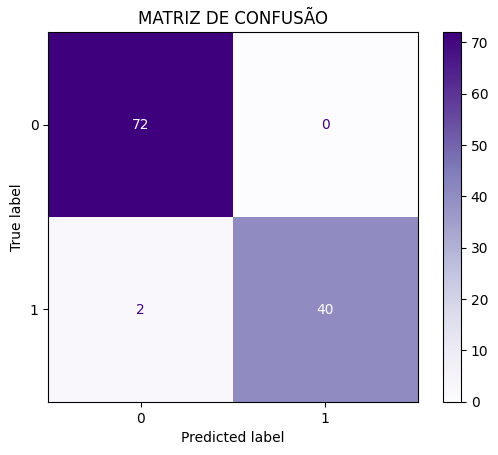

In [ ]:
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(cm).plot(cmap = 'Purples')

plt.title('MATRIZ DE CONFUSÃO')

plt.show()

## 8. Interpretações e Análises

O melhor modelo foi o SVM com kernel RBF, C = 10 e gamma = 0,01. A acurácia média na validação cruzada foi de 97,58% e, no conjunto de teste, de 98,25% (contra 97,37% do SVM com parâmetros padrão). A proximidade entre os valores de validação e teste indica boa generalização, sem sinais de overfitting. Pela matriz de confusão, todos os 72 tumores benignos foram classificados corretamente. Dos 42 malignos, 40 foram identificados e 2 foram classificados como benignos (falsos negativos), o que resulta em recall de 95,2% para a classe maligna.

# **Breast Cancer Wisconsin (Diagnostic) (Árvore de Decisão, Random Forest e Boosting)**

## 1. Importando Bibliotecas

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score)
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
import kagglehub
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

import os

df = pd.read_csv(os.path.join(path, 'data.csv'))

print(df.shape)

print(df.head())

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
(569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0

## 2. Análise dos dados e limpeza

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
print('Dados nulos: ')
print(df.isnull().sum())

Dados nulos: 
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst  

In [ ]:
print('Duplicados: ')
print(df.duplicated().sum())

Duplicados: 
0


In [ ]:
df = df.drop(columns=["Unnamed: 32", "id"], errors="ignore")
df = df.drop_duplicates()
df = df.dropna()
print(df.shape)

(569, 31)


## 3. Transformação numérica

In [ ]:
alvo = 'diagnosis'

for col in df.select_dtypes(include=['object', 'category']).columns:
  le = LabelEncoder()
  df[col] = le.fit_transform(df[col])
  print(col, ':', list(le.classes_))

print(df.dtypes)

diagnosis : ['B', 'M']
diagnosis                    int64
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst            float

## 4. Divisão X e y, treino e teste

In [ ]:
X = df.drop(columns=[alvo])

y = df[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 5. Criação e treinamento dos modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado


## 6. Previsões nos dados de teste

In [ ]:
previsoes = {nome: modelo.predict(X_test) for nome, modelo in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:  ', y_pred)

Valores reais: 120    0
250    1
375    0
99     1
455    0
      ..
381    0
534    0
448    0
205    1
75     1
Name: diagnosis, Length: 114, dtype: int64
Árvore de Decisão:   [0 1 1 1 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 1 0 0 1 0 0 1 0 0 0 1 1 0 0 0 1 1 0
 0 1 0 1 0 1 1 1 0 0 0 0 1 1 1 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 1 1]
Random Forest:   [0 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 1 1]
Gradient Boosting:   [0 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 0 1]


## 7. Avaliação e comparação



In [ ]:
resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, target_names=['Benigno', 'Maligno'], zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False)


Árvore de Decisão — Acurácia: 92.98%
              precision    recall  f1-score   support

     Benigno       0.94      0.94      0.94        72
     Maligno       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114


Random Forest — Acurácia: 97.37%
              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        72
     Maligno       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


Gradient Boosting — Acurácia: 96.49%
              precision    recall  f1-score   support

     Benigno       0.95      1.00      0.97        72
     Maligno       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg      

,Modelo,Acurácia
1,Random Forest,0.973684
2,Gradient Boosting,0.964912
0,Árvore de Decisão,0.929825


## 8. Matriz de confusão

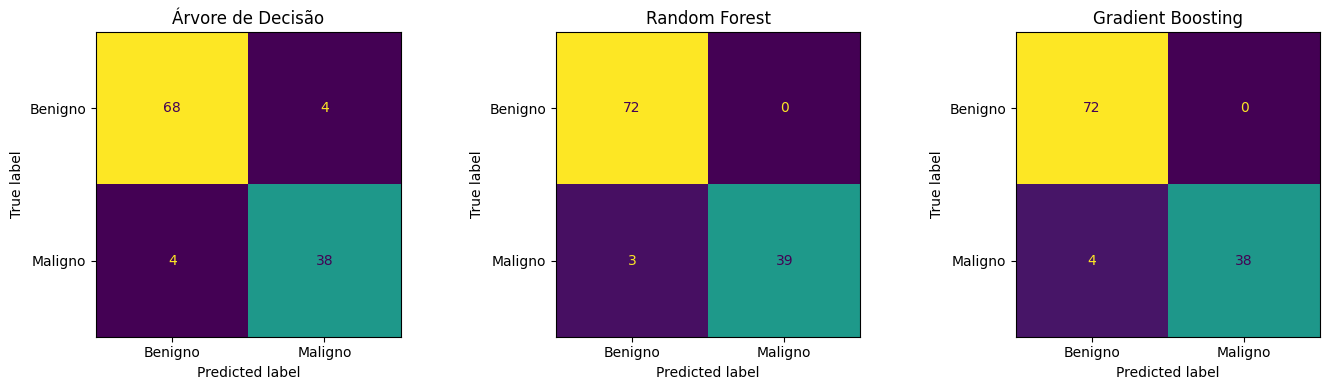

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        display_labels=['Benigno', 'Maligno'], ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

## 9. Conclusão

Foram comparados três modelos baseados em árvores: Árvore de Decisão, Random Forest e Gradient Boosting. O Random Forest teve o melhor desempenho, com acurácia de 97,37% (111 acertos em 114 amostras), seguido pelo Gradient Boosting, com 96,49%, e pela Árvore de Decisão, com 92,98%.

A Árvore de Decisão foi o modelo mais fraco e o único a errar nas duas classes: classificou 4 tumores benignos como malignos (falsos positivos) e 4 malignos como benignos (falsos negativos). Isso resultou em precisão e recall de 0,90 para a classe maligna. Esse resultado é esperado, pois uma única árvore tende a se ajustar demais aos dados de treino e generaliza pior que os métodos de ensemble.

O Random Forest e o Gradient Boosting não cometeram nenhum falso positivo: todos os 72 tumores benignos foram identificados corretamente, e a precisão da classe maligna foi de 1,00 nos dois casos. A diferença entre eles está nos falsos negativos. O Random Forest errou 3 tumores malignos (recall de 0,93), enquanto o Gradient Boosting errou 4 (recall de 0,90).

Em diagnóstico de câncer, o falso negativo é o erro mais grave, pois um tumor maligno deixa de ser identificado. Por isso o recall da classe maligna é a métrica mais relevante, e o Random Forest foi o melhor também nesse critério. Ainda assim, o conjunto de teste é pequeno (114 amostras), e a diferença entre o Random Forest e o Gradient Boosting é de apenas uma amostra, então não é possível afirmar com segurança que um seja superior ao outro.

# **COMPARAÇÃO SVM x MODELOS BASEADOS EM ÁRVORES**

In [ ]:
# COMPARAÇÃO FINAL DOS MODELOS
# Esta célula reúne as previsões dos 4 modelos (SVM com GridSearch, Random Forest,
# Gradient Boosting e Árvore de Decisão) e monta uma tabela com as mesmas métricas
# para todos, calculadas no mesmo conjunto de teste.
#
# Para cada modelo, a matriz de confusão é separada em falsos positivos (benigno
# classificado como maligno) e falsos negativos (maligno classificado como benigno).
# Com isso são calculados: acurácia, total de erros, recall e precisão da classe maligna.
#
# A tabela é ordenada pelo menor número de erros e, em caso de empate, pelo menor
# número de falsos negativos, que é o erro mais grave em diagnóstico de câncer.

previsoes_final = {'SVM (GridSearch)': grid.best_estimator_.predict(X_test), **previsoes}

linhas = []
for nome, y_pred in previsoes_final.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    linhas.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_test, y_pred),
        'Erros': fp + fn,
        'Falsos positivos': fp,
        'Falsos negativos': fn,
        'Recall (maligno)': recall_score(y_test, y_pred),
        'Precisão (maligno)': precision_score(y_test, y_pred, zero_division=0),
    })

tabela = pd.DataFrame(linhas).sort_values(['Erros', 'Falsos negativos']).reset_index(drop=True)
tabela.round(4)

,Modelo,Acurácia,Erros,Falsos positivos,Falsos negativos,Recall (maligno),Precisão (maligno)
0,SVM (GridSearch),0.9825,2,0,2,0.9524,1.0000
1,Random Forest,0.9737,3,0,3,0.9286,1.0000
2,Gradient Boosting,0.9649,4,0,4,0.9048,1.0000
3,Árvore de Decisão,0.9298,8,4,4,0.9048,0.9048


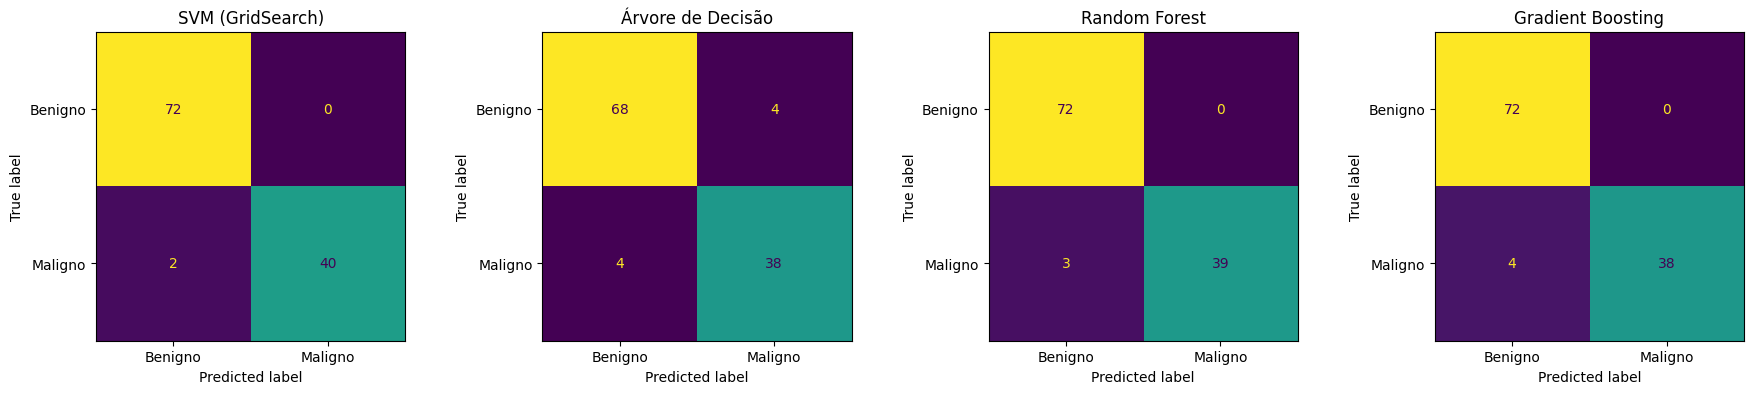

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nome, y_pred) in zip(axes, previsoes_final.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        display_labels=['Benigno', 'Maligno'], ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

Neste trabalho foram avaliados quatro classificadores para prever se um tumor é benigno ou maligno a partir de 30 características numéricas das células: SVM com ajuste de hiperparâmetros por GridSearch, Random Forest, Gradient Boosting e Árvore de Decisão. Todos foram avaliados no mesmo conjunto de teste, com 114 amostras (72 benignas e 42 malignas), o que permite uma comparação direta.

**Desempenho geral.** O SVM com kernel RBF, C = 10 e gamma = 0,01 obteve a melhor acurácia (98,25%), com apenas 2 erros em 114 amostras. Em seguida vieram o Random Forest (97,37%, 3 erros), o Gradient Boosting (96,49%, 4 erros) e a Árvore de Decisão (92,98%, 8 erros). A acurácia média do SVM na validação cruzada foi de 97,58%, próxima à do teste, o que indica boa capacidade de generalização e ausência de sinais de overfitting.

**Modelos baseados em árvores.** A Árvore de Decisão foi a de pior desempenho e a única a errar nas duas classes: classificou 4 tumores benignos como malignos e 4 malignos como benignos, com precisão e recall de 0,90 na classe maligna. Isso é coerente com o comportamento de árvores individuais, que tendem a se ajustar demais aos dados de treino e a variar bastante com pequenas mudanças nos dados. Os métodos de ensemble corrigiram esse problema ao combinar várias árvores. O Random Forest (que faz a média de árvores independentes) e o Gradient Boosting (que treina árvores em sequência, corrigindo os erros das anteriores) reduziram os erros de 8 para 3 e 4, respectivamente, e eliminaram os falsos positivos.

**Análise por tipo de erro.** Em diagnóstico médico, os dois tipos de erro têm custos diferentes. O falso positivo (benigno classificado como maligno) gera exames adicionais e ansiedade, mas é corrigível. O falso negativo (maligno classificado como benigno) é o mais grave, pois pode atrasar o tratamento. Por isso o recall da classe maligna é a métrica mais importante. O SVM teve o melhor recall (95,2%, com 2 falsos negativos), seguido pelo Random Forest (92,9%, com 3) e pelo Gradient Boosting e a Árvore de Decisão (90,5%, com 4 cada). Random Forest, Gradient Boosting e SVM tiveram precisão de 100% na classe maligna, ou seja, todo tumor classificado como maligno realmente era maligno.

**SVM versus ensembles.** O bom desempenho do SVM é compatível com a natureza dos dados: as 30 variáveis são numéricas, contínuas e muito correlacionadas entre si (por exemplo, raio, perímetro e área). Após a padronização das variáveis, o SVM consegue traçar uma fronteira de decisão suave, o que é adequado a esse tipo de dado. O GridSearch selecionou o kernel RBF entre os quatro testados, mas a diferença para os demais kernels (em especial o linear) pode ser pequena, como mostra a tabela de acurácia por kernel na seção 6 da primeira parte; por isso não é possível concluir, apenas com esses resultados, que a relação entre as variáveis e o diagnóstico seja fortemente não linear.

**Limitações.** O conjunto de teste é pequeno, e cada erro equivale a cerca de 0,9 ponto percentual de acurácia. A diferença entre o SVM (2 erros) e o Random Forest (3 erros) é de uma única amostra, portanto não é suficiente para afirmar que um seja superior ao outro. Já a diferença em relação à Árvore de Decisão (8 erros) é mais expressiva. Além disso, o SVM passou por ajuste de hiperparâmetros com GridSearch, enquanto os modelos de árvores foram avaliados com os parâmetros padrão, o que favorece o SVM na comparação. Para uma análise mais robusta, seria recomendável avaliar todos os modelos com validação cruzada repetida e aplicar o mesmo ajuste de hiperparâmetros aos modelos de árvores.

**Conclusão.** O SVM com GridSearch obteve o melhor resultado, com a maior acurácia e o maior recall para a classe maligna, seguido de perto pelo Random Forest, com diferença de uma amostra. Entre os modelos de árvores, os ensembles superaram com folga a árvore individual. Todos os modelos, exceto a Árvore de Decisão, tiveram precisão perfeita na classe maligna.

# **Literary Digest 1936 com Regressão Linear Simples (voto de 1932 como âncora)**

## 1. Fazendo as importações e visualizando o dataset

In [ ]:
# No Colab, execute esta célula e selecione o arquivo LitDigestFull.xlsx no seu computador
from google.colab import files

uploaded = files.upload()
arquivo = list(uploaded.keys())[0]
print(arquivo)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# a planilha tem uma aba por eleição; aqui usamos as abas de 1932 e 1936
# header=None porque as abas têm cabeçalho de 2 linhas e vários blocos lado a lado
aba_1932 = pd.read_excel(arquivo, sheet_name='1932', header=None)
aba_1936 = pd.read_excel(arquivo, sheet_name='1936', header=None)

print(aba_1932.shape)
print(aba_1936.shape)
print(aba_1936.iloc[:5, :12])

## 2. Tratando os dados

In [ ]:
# resultado real de 1932 (bloco da direita da aba 1932): coluna 27 = estado, coluna 30 = % de Roosevelt
real_1932 = aba_1932.iloc[1:, [27, 30]].copy()
real_1932.columns = ['estado', 'roosevelt_1932']

# resultado real de 1936 (bloco da direita da aba 1936): coluna 34 = estado, 37 = % de Roosevelt, 40 = % de Landon
real_1936 = aba_1936.iloc[1:, [34, 37, 40]].copy()
real_1936.columns = ['estado', 'roosevelt_1936', 'landon_1936']

# pesquisa de 1936 (bloco da esquerda da aba 1936, uma linha por estado a partir da linha 2):
# coluna 0 = estado, 2 = votos em Landon, 10 = votos em Roosevelt, 32 = total de respostas
pesquisa = aba_1936.iloc[2:, [0, 2, 10, 32]].copy()
pesquisa.columns = ['estado', 'votos_landon', 'votos_roosevelt', 'respostas']

# como os entrevistados disseram ter votado em 1932 (somando os eleitores de Landon, Roosevelt e Lemke):
# Rep. = colunas 3, 11, 19 | Dem. = 4, 12, 20 | Soc. = 5, 13, 21 | Outros = 6, 14, 22
rep = aba_1936.iloc[2:, [3, 11, 19]].astype(float).sum(axis=1)
dem = aba_1936.iloc[2:, [4, 12, 20]].astype(float).sum(axis=1)
soc = aba_1936.iloc[2:, [5, 13, 21]].astype(float).sum(axis=1)
outros = aba_1936.iloc[2:, [6, 14, 22]].astype(float).sum(axis=1)

# % de Roosevelt (democrata) no voto de 1932 lembrado pelos entrevistados, entre quem votou em 1932
pesquisa['lembrado_1932'] = dem / (rep + dem + soc + outros) * 100

# padroniza os nomes dos estados
for tabela in [real_1932, real_1936, pesquisa]:
    tabela['estado'] = tabela['estado'].astype(str).str.strip()

# junta as três tabelas pelo nome do estado (linhas como 'Totals' e 'State Unknown' ficam de fora)
eleicoes = real_1932.merge(real_1936, on='estado').merge(pesquisa, on='estado')

# garante que tudo é numérico (valores como '-' viram nulos)
for col in eleicoes.columns.drop('estado'):
    eleicoes[col] = pd.to_numeric(eleicoes[col], errors='coerce')

# proporções da pesquisa de 1936 = votos / total de respostas
eleicoes['pesquisa_1936'] = eleicoes['votos_roosevelt'] / eleicoes['respostas'] * 100
eleicoes['pesquisa_landon_1936'] = eleicoes['votos_landon'] / eleicoes['respostas'] * 100
eleicoes = eleicoes.drop(columns=['votos_roosevelt', 'votos_landon'])

# viés de 1932: quanto a amostra erra o voto passado conhecido (lembrado - real)
eleicoes['vies_1932'] = eleicoes['lembrado_1932'] - eleicoes['roosevelt_1932']

# erro de 1936: quanto a pesquisa erra o voto que depois foi conhecido (pesquisa - real)
eleicoes['erro_1936'] = eleicoes['pesquisa_1936'] - eleicoes['roosevelt_1936']

print(eleicoes.shape)
print(eleicoes.head())

In [ ]:
print(eleicoes.info())

In [ ]:
print('Dados nulos: ')
print(eleicoes.isnull().sum())

In [ ]:
print ('Duplicados: ')
print(eleicoes.duplicated().sum())

In [ ]:
# eleicoes = eleicoes.dropna() não foi necessário pois não tinha dados nulos

In [ ]:
# eleicoes = eleicoes.drop_duplicates() não foi necessário pois não tinha dados duplicados

In [ ]:
# o nome do estado vira o índice: identifica cada linha, mas não entra no modelo
eleicoes = eleicoes.set_index('estado')

print(eleicoes.shape)

In [ ]:
print(eleicoes.info())

## 3. Análise exploratória: proporções de votos e discrepâncias estaduais

In [ ]:
print(eleicoes.describe().round(2))

In [ ]:
# resultado nacional: pesquisa (média dos estados ponderada pelo número de respostas) x resultado real (linha 'TOTALS:' da planilha)
linha_total = aba_1936[aba_1936[34].astype(str).str.strip() == 'TOTALS:']
real_roosevelt = float(linha_total[37].iloc[0])
real_landon = float(linha_total[40].iloc[0])

pesquisa_roosevelt = np.average(eleicoes['pesquisa_1936'], weights=eleicoes['respostas'])
pesquisa_landon = np.average(eleicoes['pesquisa_landon_1936'], weights=eleicoes['respostas'])

nacional = pd.DataFrame({
    'Pesquisa (%)': [pesquisa_roosevelt, pesquisa_landon],
    'Real (%)': [real_roosevelt, real_landon],
}, index=['Roosevelt', 'Landon'])
nacional['Diferença (p.p.)'] = nacional['Pesquisa (%)'] - nacional['Real (%)']
nacional.round(2)

In [ ]:
# discrepância estadual do Landon (pesquisa - real); a de Roosevelt já está em 'erro_1936'
eleicoes['erro_landon_1936'] = eleicoes['pesquisa_landon_1936'] - eleicoes['landon_1936']

print('Estados com maior subestimação de Roosevelt (p.p.): ')
print(eleicoes['erro_1936'].sort_values().head(5).round(2))

# vencedor em cada estado = candidato com maior proporção
vencedor_real = np.where(eleicoes['roosevelt_1936'] > eleicoes['landon_1936'], 'Roosevelt', 'Landon')
vencedor_pesquisa = np.where(eleicoes['pesquisa_1936'] > eleicoes['pesquisa_landon_1936'], 'Roosevelt', 'Landon')

print('Estados em que a pesquisa errou o vencedor: ', (vencedor_real != vencedor_pesquisa).sum(), 'de', len(eleicoes))
print('Estados vencidos por Roosevelt -> real: ', (vencedor_real == 'Roosevelt').sum(), '| pesquisa: ', (vencedor_pesquisa == 'Roosevelt').sum())

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1) % de Roosevelt na pesquisa x real (a linha tracejada seria a pesquisa perfeita)
axes[0].scatter(eleicoes['roosevelt_1936'], eleicoes['pesquisa_1936'])
limites = [eleicoes['pesquisa_1936'].min() - 2, eleicoes['roosevelt_1936'].max() + 2]
axes[0].plot(limites, limites, 'k--', label='Pesquisa perfeita')
axes[0].set_xlabel('% de Roosevelt real em 1936')
axes[0].set_ylabel('% de Roosevelt na pesquisa')
axes[0].set_title('Pesquisa x resultado real (48 estados)')
axes[0].legend()

# 2) distribuição do erro da pesquisa
axes[1].hist(eleicoes['erro_1936'], bins=10)
axes[1].axvline(0, color='k', linestyle='--')
axes[1].set_xlabel('Erro da pesquisa (pesquisa - real, p.p.)')
axes[1].set_ylabel('Número de estados')
axes[1].set_title('Erro da pesquisa em 1936')

plt.tight_layout()
plt.show()

## 4. Diagnóstico de viés

In [ ]:
# viés de amostragem: a amostra tem a mesma composição de voto de 1932 que o eleitorado real?
print('Viés médio de 1932 (lembrado - real, p.p.): ', eleicoes['vies_1932'].mean())
print('Estados em que a amostra lembrou menos Roosevelt do que o resultado real de 1932: ', (eleicoes['vies_1932'] < 0).sum(), 'de', len(eleicoes))

In [ ]:
# viés de não-resposta: a planilha não traz o número de cartões enviados por estado,
# então usamos o dado do enunciado: cerca de 10 milhões de cartões enviados em 1936
cartoes_enviados = 10_000_000
respostas_total = aba_1936[aba_1936[0].astype(str).str.strip() == 'Totals'][32].iloc[0]

print('Respostas recebidas: ', respostas_total)
print('Taxa de resposta (%): ', respostas_total / cartoes_enviados * 100)

In [ ]:
# do erro total da pesquisa, quanto é explicado pelo viés de 1932 e quanto sobra
eleicoes['vies_restante'] = eleicoes['erro_1936'] - eleicoes['vies_1932']

print('Erro médio total da pesquisa (p.p.): ', eleicoes['erro_1936'].mean())
print('  explicado pelo viés de 1932 (amostragem): ', eleicoes['vies_1932'].mean())
print('  restante (não explicado pelo voto de 1932): ', eleicoes['vies_restante'].mean())

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1) voto de 1932 lembrado pelos entrevistados x resultado real de 1932
axes[0].scatter(eleicoes['roosevelt_1932'], eleicoes['lembrado_1932'])
limites = [eleicoes['lembrado_1932'].min() - 2, eleicoes['roosevelt_1932'].max() + 2]
axes[0].plot(limites, limites, 'k--', label='Amostra sem viés')
axes[0].set_xlabel('% de Roosevelt real em 1932')
axes[0].set_ylabel('% de Roosevelt lembrado pelos entrevistados')
axes[0].set_title('Viés de amostragem (1932)')
axes[0].legend()

# 2) decomposição do erro médio da pesquisa
valores = [eleicoes['vies_1932'].mean(), eleicoes['vies_restante'].mean(), eleicoes['erro_1936'].mean()]
axes[1].bar(['Viés de 1932', 'Restante', 'Erro total'], valores, color=['tab:blue', 'tab:gray', 'tab:red'])
axes[1].axhline(0, color='k', linewidth=0.8)
axes[1].set_ylabel('Pontos percentuais')
axes[1].set_title('Decomposição do erro médio da pesquisa')

plt.tight_layout()
plt.show()

Viés de amostragem. Em média, os entrevistados lembraram um voto em Roosevelt em 1932 8,87 pontos percentuais abaixo do resultado real, e isso ocorreu em 43 dos 48 estados: a amostra tinha menos eleitores democratas do que o eleitorado de 1932. Esse viés é medido com um dado já conhecido (o resultado de 1932), e é por isso que ele serve de âncora.

Viés de não-resposta. O enunciado informa cerca de 10 milhões de cartões enviados, e a planilha registra 2.376.523 respostas, uma taxa de resposta de 23,8%. A planilha não traz o número de cartões enviados por estado nem informações sobre quem respondeu, então o viés de não-resposta não pode ser medido diretamente. O que se consegue quantificar é a parte do erro que o voto de 1932 não explica: do erro médio de −18,72 pontos percentuais, −8,87 correspondem ao viés de 1932 e −9,85 ficam sem explicação. Esse restante é compatível com não-resposta, mas também com outras fontes de erro, e os dados não permitem separá-las.

## 5. Definindo um alvo e tratando dados não numéricos

In [ ]:
alvo = 'erro_1936'
#esse laço for não era necessário, mas decidi manter pois é essencial tratar dados não-numéricos, já que o modelo so trabalha com dados numéricos.
for col in eleicoes.select_dtypes(include=['object', 'category']).columns:
  le = LabelEncoder()
  eleicoes[col] = le.fit_transform(eleicoes[col])
  print(col, ':', list(le.classes_)) #esse so funciona se for do tipo str, como ele ja era numerico, não roda

print(eleicoes.dtypes)

## 6. Dividindo os dados em X e y

In [ ]:
# regressão linear SIMPLES: uma única variável explicativa, o viés do voto de 1932 (âncora)
X = eleicoes[['vies_1932']]

y = eleicoes[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42
)

# pesquisa original e resultado real de 1936 nos estados de teste (só para corrigir e comparar, não entram no modelo)
pesquisa_test = eleicoes.loc[X_test.index, 'pesquisa_1936']
real_test = eleicoes.loc[X_test.index, 'roosevelt_1936']

cv = KFold(n_splits=5, random_state=42, shuffle=True)

## 7. Regressão linear simples com 1932 como âncora

In [ ]:
model = LinearRegression()

# validação cruzada no treino
r2_cv = cross_val_score(model, X_train, y_train, cv=cv, scoring='r2')
mae_cv = -cross_val_score(model, X_train, y_train, cv=cv, scoring='neg_mean_absolute_error')

model.fit(X_train, y_train)

print('Coeficiente (inclinação): ', model.coef_[0])
print('Intercepto: ', model.intercept_)
print(f'erro_1936 = {model.intercept_:.2f} + {model.coef_[0]:.2f} x vies_1932')

## 8. Resultados

In [ ]:
print('Modelo: Regressão Linear Simples')

# erro previsto pelo modelo e previsão corrigida = pesquisa original - erro previsto
y_pred = model.predict(X_test)
pesquisa_corrigida = pesquisa_test - y_pred

print('R2 na validação cruzada: ', r2_cv.mean())
print('MAE na validação cruzada (pontos percentuais): ', mae_cv.mean())
print('R2 no teste (erro previsto): ', r2_score(y_test, y_pred))
print('MAE da pesquisa original no teste (pontos percentuais): ', mean_absolute_error(real_test, pesquisa_test))
print('MAE da pesquisa corrigida no teste (pontos percentuais): ', mean_absolute_error(real_test, pesquisa_corrigida))

In [ ]:
resultado_teste = pd.DataFrame({
    'Real 1936': real_test,
    'Pesquisa original': pesquisa_test,
    'Pesquisa corrigida': pesquisa_corrigida,
})
resultado_teste['Erro original'] = resultado_teste['Pesquisa original'] - resultado_teste['Real 1936']
resultado_teste['Erro corrigido'] = resultado_teste['Pesquisa corrigida'] - resultado_teste['Real 1936']
resultado_teste.round(2)

## 9. Gráficos

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1) viés de 1932 x erro de 1936, com a reta da regressão
axes[0].scatter(X_train['vies_1932'], y_train, label='Treino')
axes[0].scatter(X_test['vies_1932'], y_test, color='orange', label='Teste')
x_linha = np.linspace(X['vies_1932'].min(), X['vies_1932'].max(), 100)
axes[0].plot(x_linha, model.intercept_ + model.coef_[0] * x_linha, color='red', label='Reta da regressão')
axes[0].set_xlabel('Viés de 1932 (lembrado - real, p.p.)')
axes[0].set_ylabel('Erro da pesquisa em 1936 (pesquisa - real, p.p.)')
axes[0].set_title('Regressão linear simples')
axes[0].legend()

# 2) real x previsto (% de Roosevelt em 1936) nos estados de teste
axes[1].scatter(real_test, pesquisa_test, label='Pesquisa original')
axes[1].scatter(real_test, pesquisa_corrigida, label='Pesquisa corrigida')
limites = [min(real_test.min(), pesquisa_test.min()) - 2, max(real_test.max(), pesquisa_test.max()) + 2]
axes[1].plot(limites, limites, 'k--', label='Previsão perfeita')
axes[1].set_xlabel('% de Roosevelt real em 1936')
axes[1].set_ylabel('% de Roosevelt previsto')
axes[1].set_title('Estados de teste')
axes[1].legend()

plt.tight_layout()
plt.show()

## 10. Conclusão

O modelo de regressão linear simples estimou o erro da pesquisa de 1936 a partir do viés de 1932 (percentual de Roosevelt lembrado pelos entrevistados menos o resultado real de 1932), e a equação encontrada foi erro_1936 = −10,41 + 0,93 × vies_1932. O R² foi de 0,59 na validação cruzada e de 0,81 no teste, e o teste ficou acima da validação, o que indica que o modelo generaliza, sem sinais de overfitting, embora o teste tenha apenas 10 estados. O coeficiente positivo e próximo de 1 mostra que cada ponto percentual a menos de Roosevelt na amostra de 1932 se repetiu em cerca de 0,93 ponto de subestimação em 1936. O intercepto de −10,41 indica que, mesmo sem viés de recordação em 1932, a pesquisa ainda subestimaria Roosevelt em cerca de 10 pontos, ou seja, parte do erro não é explicada pelo voto passado. Ao subtrair o erro previsto da pesquisa original, o erro médio absoluto (MAE) nos estados de teste caiu de 20,87 para 2,05 pontos percentuais.

# **Literary Digest 1936 com Árvore de decisão, Random Forest e Boosting**

## 1. Importando bibliotecas

In [ ]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
aba_1932 = pd.read_excel(arquivo, sheet_name='1932', header=None)
aba_1936 = pd.read_excel(arquivo, sheet_name='1936', header=None)

print(aba_1932.shape)
print(aba_1936.shape)

## 2. Análise dos dados e limpeza

In [ ]:
# resultado real de 1932 (bloco da direita da aba 1932): coluna 27 = estado, coluna 30 = % de Roosevelt
real_1932 = aba_1932.iloc[1:, [27, 30]].copy()
real_1932.columns = ['estado', 'roosevelt_1932']

# resultado real de 1936 (bloco da direita da aba 1936): coluna 34 = estado, 37 = % de Roosevelt, 40 = % de Landon
real_1936 = aba_1936.iloc[1:, [34, 37, 40]].copy()
real_1936.columns = ['estado', 'roosevelt_1936', 'landon_1936']

# pesquisa de 1936 (bloco da esquerda da aba 1936, uma linha por estado a partir da linha 2):
# coluna 0 = estado, 2 = votos em Landon, 10 = votos em Roosevelt, 32 = total de respostas
pesquisa = aba_1936.iloc[2:, [0, 2, 10, 32]].copy()
pesquisa.columns = ['estado', 'votos_landon', 'votos_roosevelt', 'respostas']

# como os entrevistados disseram ter votado em 1932 (somando os eleitores de Landon, Roosevelt e Lemke):
# Rep. = colunas 3, 11, 19 | Dem. = 4, 12, 20 | Soc. = 5, 13, 21 | Outros = 6, 14, 22
rep = aba_1936.iloc[2:, [3, 11, 19]].astype(float).sum(axis=1)
dem = aba_1936.iloc[2:, [4, 12, 20]].astype(float).sum(axis=1)
soc = aba_1936.iloc[2:, [5, 13, 21]].astype(float).sum(axis=1)
outros = aba_1936.iloc[2:, [6, 14, 22]].astype(float).sum(axis=1)

# % de Roosevelt (democrata) no voto de 1932 lembrado pelos entrevistados, entre quem votou em 1932
pesquisa['lembrado_1932'] = dem / (rep + dem + soc + outros) * 100

# padroniza os nomes dos estados
for tabela in [real_1932, real_1936, pesquisa]:
    tabela['estado'] = tabela['estado'].astype(str).str.strip()

# junta as três tabelas pelo nome do estado (linhas como 'Totals' e 'State Unknown' ficam de fora)
eleicoes = real_1932.merge(real_1936, on='estado').merge(pesquisa, on='estado')

# garante que tudo é numérico (valores como '-' viram nulos)
for col in eleicoes.columns.drop('estado'):
    eleicoes[col] = pd.to_numeric(eleicoes[col], errors='coerce')

# proporções da pesquisa de 1936 = votos / total de respostas
eleicoes['pesquisa_1936'] = eleicoes['votos_roosevelt'] / eleicoes['respostas'] * 100
eleicoes['pesquisa_landon_1936'] = eleicoes['votos_landon'] / eleicoes['respostas'] * 100
eleicoes = eleicoes.drop(columns=['votos_roosevelt', 'votos_landon'])

# viés de 1932: quanto a amostra erra o voto passado conhecido (lembrado - real)
eleicoes['vies_1932'] = eleicoes['lembrado_1932'] - eleicoes['roosevelt_1932']

# erro de 1936: quanto a pesquisa erra o voto que depois foi conhecido (pesquisa - real)
eleicoes['erro_1936'] = eleicoes['pesquisa_1936'] - eleicoes['roosevelt_1936']

print(eleicoes.shape)
print(eleicoes.head())

In [ ]:
print(eleicoes.info())

In [ ]:
print('Dados nulos: ')
print(eleicoes.isnull().sum())

In [ ]:
print('Duplicados: ')
print(eleicoes.duplicated().sum())

In [ ]:
#eleicoes = eleicoes.drop(columns=["id"]) não existe nenhuma coluna de identificação
eleicoes = eleicoes.drop_duplicates()
eleicoes = eleicoes.dropna()
eleicoes = eleicoes.set_index('estado')
print(eleicoes.shape)

## 3. Transformação numérica

In [ ]:
alvo = 'erro_1936'

for col in eleicoes.select_dtypes(include=['object', 'category']).columns:
  le = LabelEncoder()
  eleicoes[col] = le.fit_transform(eleicoes[col])
  print(col, ':', list(le.classes_))

print(eleicoes.dtypes)

## 4. Divisão X e y, treino e teste

In [ ]:
# mesma variável explicativa da regressão linear simples: o viés do voto de 1932
X = eleicoes[['vies_1932']]

y = eleicoes[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42
)

pesquisa_test = eleicoes.loc[X_test.index, 'pesquisa_1936']
real_test = eleicoes.loc[X_test.index, 'roosevelt_1936']

## 5. Criação e treinamento dos modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f'{nome}: treinado')

## 6. Previsões nos dados de teste

In [ ]:
previsoes = {nome: modelo.predict(X_test) for nome, modelo in modelos.items()}
print('Erro real da pesquisa:', np.round(y_test.values, 2))
for nome, y_pred in previsoes.items():
    print(f'{nome}:  ', np.round(y_pred, 2))

## 7. Avaliação e comparação

In [ ]:
resultados = []
for nome, y_pred in previsoes.items():
    corrigida = pesquisa_test - y_pred
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(real_test, corrigida)
    rmse = np.sqrt(mean_squared_error(real_test, corrigida))
    resultados.append({'Modelo': nome, 'R2 (erro previsto)': r2, 'MAE (pesquisa corrigida)': mae, 'RMSE (pesquisa corrigida)': rmse})
    print(f'\n{nome} — R2 do erro previsto: {r2:.2%} | MAE da pesquisa corrigida: {mae:.2f} p.p.')
pd.DataFrame(resultados).sort_values('MAE (pesquisa corrigida)').round(4)

## 8. Gráficos

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
limites = [min(real_test.min(), pesquisa_test.min()) - 2, max(real_test.max(), pesquisa_test.max()) + 2]
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ax.scatter(real_test, pesquisa_test, color='lightgray', label='Pesquisa original')
    ax.scatter(real_test, pesquisa_test - y_pred, label='Pesquisa corrigida')
    ax.plot(limites, limites, 'k--', label='Previsão perfeita')
    ax.set_xlabel('% de Roosevelt real em 1936')
    ax.set_ylabel('% de Roosevelt previsto')
    ax.set_title(nome)
    ax.legend()
plt.tight_layout()
plt.show()

## 9. Conclusão

Foram comparados três modelos baseados em árvores: Árvore de Decisão, Random Forest e Gradient Boosting, todos com parâmetros padrão e com a mesma variável da regressão (viés de 1932). O Random Forest teve o melhor desempenho, com MAE de 2,15 pontos percentuais na pesquisa corrigida e R² de 0,79 ao prever o erro, seguido pelo Gradient Boosting (MAE de 2,69 e R² de 0,71) e pela Árvore de Decisão (MAE de 2,75 e R² de 0,67).

A Árvore de Decisão foi o modelo mais fraco, com RMSE de 3,41. Esse resultado é esperado, pois uma única árvore tende a se ajustar demais aos dados de treino e, com apenas 38 estados de treino, ela prevê o erro por degraus, usando médias de pequenos grupos de estados. O Random Forest, que faz a média de várias árvores independentes, foi o que mais reduziu esse problema (MAE de 2,75 para 2,15), enquanto o Gradient Boosting reduziu pouco (para 2,69).

Os três modelos ficaram com erro médio levemente positivo (entre 0,61 e 0,79 ponto), ou seja, em média superestimaram Roosevelt em menos de 1 ponto, e todos acertaram a maioria (Roosevelt acima de 50%) em 9 dos 10 estados de teste. Ainda assim, o teste tem apenas 10 estados, e a vantagem do Random Forest sobre os outros dois é de 0,5 a 0,6 ponto de MAE, o que sugere, mas não prova, que ele seja superior.

# **COMPARAÇÃO REGRESSÃO LINEAR x MODELOS BASEADOS EM ÁRVORES**

In [ ]:
# COMPARAÇÃO FINAL DOS MODELOS
# Esta célula reúne as previsões da pesquisa original e das pesquisas corrigidas por 4 modelos
# (Regressão Linear Simples, Árvore de Decisão, Random Forest e Gradient Boosting) e monta
# uma tabela com as mesmas métricas para todos, no mesmo conjunto de teste.
#
# A previsão corrigida de cada modelo é: pesquisa original - erro previsto pelo modelo.
# São calculados: MAE, RMSE, R2, erro médio (negativo = subestimou Roosevelt)
# e acertos de maioria (estados em que Roosevelt ficou acima de 50% e a previsão acertou isso).
#
# A tabela é ordenada pelo menor MAE.
# Obs.: nenhum dos modelos passou por ajuste de hiperparâmetros; todos usam apenas o viés de 1932.

previsoes_final = {
    'Pesquisa original': pesquisa_test,
    'Regressão Linear Simples': pesquisa_test - model.predict(X_test),
    **{nome: pesquisa_test - y_pred for nome, y_pred in previsoes.items()}
}

linhas = []
for nome, previsao in previsoes_final.items():
    linhas.append({
        'Modelo': nome,
        'MAE': mean_absolute_error(real_test, previsao),
        'RMSE': np.sqrt(mean_squared_error(real_test, previsao)),
        'R2': r2_score(real_test, previsao),
        'Erro médio': (previsao - real_test).mean(),
        'Acertos de maioria': int(((previsao > 50) == (real_test > 50)).sum()),
    })

tabela = pd.DataFrame(linhas).sort_values('MAE').reset_index(drop=True)
tabela.round(4)

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
limites = [min(real_test.min(), pesquisa_test.min()) - 2, max(real_test.max(), pesquisa_test.max()) + 2]
for ax, (nome, previsao) in zip(axes, list(previsoes_final.items())[1:]):
    ax.scatter(real_test, pesquisa_test, color='lightgray', label='Pesquisa original')
    ax.scatter(real_test, previsao, label='Pesquisa corrigida')
    ax.plot(limites, limites, 'k--', label='Previsão perfeita')
    ax.set_xlabel('% de Roosevelt real em 1936')
    ax.set_ylabel('% de Roosevelt previsto')
    ax.set_title(nome)
    ax.legend()
plt.tight_layout()
plt.show()

Neste trabalho foram avaliados quatro modelos para corrigir a previsão da pesquisa do Literary Digest de 1936 (percentual de votos em Roosevelt por estado) usando o voto de 1932 como âncora: Regressão Linear Simples, Árvore de Decisão, Random Forest e Gradient Boosting. Todos preveem o erro da pesquisa a partir do viés de 1932 (percentual de Roosevelt lembrado pelos entrevistados menos o resultado real de 1932), e a previsão corrigida é a pesquisa original menos o erro previsto. Os modelos foram avaliados no mesmo conjunto de teste, com 10 dos 48 estados, o que permite uma comparação direta com a pesquisa original.

Desempenho geral. A Regressão Linear Simples obteve o menor MAE (2,05 pontos percentuais), seguida pelo Random Forest (2,15), pelo Gradient Boosting (2,69) e pela Árvore de Decisão (2,75). A pesquisa original teve MAE de 20,87, então todos os modelos reduziram o erro em pelo menos 87%, e a regressão em 90%. O RMSE seguiu a mesma ordem (2,58; 2,77; 3,22; 3,41), e o R² das previsões corrigidas ficou entre 0,95 e 0,97, contra −1,13 da pesquisa original (o valor negativo indica que ela errava mais do que simplesmente prever a média dos estados).

Análise por tipo de erro. O erro médio da regressão foi de −0,09 ponto (praticamente sem viés), enquanto os modelos de árvore ficaram entre 0,61 e 0,79, superestimando levemente Roosevelt. Os acertos de maioria foram iguais: 9 de 10 estados nos quatro modelos, contra 4 de 10 da pesquisa original. O único estado errado por todos foi New Hampshire, onde Roosevelt teve 49,73% e as previsões corrigidas ficaram acima de 50%.

Regressão versus árvores. A relação entre o viés de 1932 e o erro de 1936 é aproximadamente linear (gráfico da seção 9 da primeira parte), o que favorece a regressão linear simples, que tem apenas dois parâmetros. Já as árvores aproximam essa reta por degraus, usando médias de grupos de estados, e com apenas 38 estados de treino e uma única variável não têm informação extra para capturar além da reta. Por isso os modelos de árvore não superaram a regressão, e a diferença para o Random Forest (0,10 ponto de MAE) é pequena.

Limitações. O conjunto de teste tem apenas 10 estados, então cada estado pesa bastante nas métricas, e a diferença de 0,10 ponto entre a regressão e o Random Forest não permite afirmar que uma seja superior à outra. Os modelos de árvore usaram parâmetros padrão, sem ajuste, e todos usaram só o viés de 1932; com mais variáveis ou ajuste de hiperparâmetros o resultado poderia mudar. Além disso, o viés de 1932 vem do voto lembrado pelos entrevistados e pode diferir do voto real. Para uma análise mais robusta, seria recomendável avaliar os modelos com validação cruzada repetida nos 48 estados.

Conclusão. A Regressão Linear Simples e o Random Forest tiveram desempenho praticamente igual (MAE de 2,05 e 2,15 pontos percentuais), à frente do Gradient Boosting e da Árvore de Decisão. Todos os modelos corrigiram boa parte do erro da pesquisa original (MAE de 20,87), o que mostra que o voto de 1932, já conhecido antes de 1936, é uma âncora útil. Como a regressão é mais simples e interpretável e não ficou atrás das árvores, ela é a escolha mais adequada para este problema, ressalvando o tamanho do conjunto de teste.

# **UCI Heart Disease Data - Modelo SVM com 4 kernels, C e gamma**

## 1. Importando bibliotecas e carregando o dataset

In [ ]:
import kagglehub
path = kagglehub.dataset_download("redwankarimsony/heart-disease-data")

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import os

dcardiaca = pd.read_csv(os.path.join(path, 'heart_disease_uci.csv'))

print(dcardiaca.shape)

print(dcardiaca.head())

100%|██████████| 12.4k/12.4k [00:00<00:00, 6.98MB/s]

Extracting files...


(920, 16)
   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  num  
0       fixed defect    0  
1             normal    2  
2  reversable defect    1  
3             normal    0  
4             normal    0 

## 2. Análise de dados e limpeza

In [ ]:
print(dcardiaca.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB
None


In [ ]:
print('Dados nulos: ')
print(dcardiaca.isnull().sum())

Dados nulos: 
id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


In [ ]:
# a coluna 'id' é só um identificador do paciente e não ajuda o modelo, então é removida
dcardiaca = dcardiaca.drop(columns=['id'])

In [ ]:
print('Duplicados: ')
print(dcardiaca.duplicated().sum())

Duplicados: 
2


In [ ]:
dcardiaca = dcardiaca.drop_duplicates()

In [ ]:
# em trestbps (pressão) e chol (colesterol) o valor 0 é impossível: são valores ausentes disfarçados
print('Zeros em trestbps e chol: ')
print((dcardiaca[['trestbps', 'chol']] == 0).sum())

dcardiaca[['trestbps', 'chol']] = dcardiaca[['trestbps', 'chol']].mask(dcardiaca[['trestbps', 'chol']] == 0)

Zeros em trestbps e chol: 
trestbps      1
chol        172
dtype: int64


In [ ]:
# preenchimento dos dados nulos:
# mediana nas colunas numéricas contínuas (não é afetada por valores extremos)
# moda nas colunas de texto, verdadeiro/falso e de contagem (ca), pois é o valor mais frequente
colunas_mediana = ['trestbps', 'chol', 'thalch', 'oldpeak']
colunas_moda = ['fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

for col in colunas_mediana:
    dcardiaca[col] = dcardiaca[col].fillna(dcardiaca[col].median())

for col in colunas_moda:
    dcardiaca[col] = dcardiaca[col].fillna(dcardiaca[col].mode()[0])

print('Dados nulos após o preenchimento: ')
print(dcardiaca.isnull().sum())

Dados nulos após o preenchimento: 
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


/tmp/ipykernel_6044/984118661.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dcardiaca[col] = dcardiaca[col].fillna(dcardiaca[col].mode()[0])


In [ ]:
print(dcardiaca.shape)

print(dcardiaca.info())

(918, 15)
<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 0 to 919
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   dataset   918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  918 non-null    float64
 5   chol      918 non-null    float64
 6   fbs       918 non-null    bool   
 7   restecg   918 non-null    object 
 8   thalch    918 non-null    float64
 9   exang     918 non-null    bool   
 10  oldpeak   918 non-null    float64
 11  slope     918 non-null    object 
 12  ca        918 non-null    float64
 13  thal      918 non-null    object 
 14  num       918 non-null    int64  
dtypes: bool(2), float64(5), int64(2), object(6)
memory usage: 102.2+ KB
None


## 3. Definindo um alvo e tratando dados não numéricos

In [ ]:
alvo = 'num'

# a coluna 'num' vai de 0 (sem doença) a 4 (níveis de doença); aqui o alvo é binário: 0 = sem doença, 1 = com doença
dcardiaca[alvo] = (dcardiaca[alvo] > 0).astype(int)

# colunas de texto (sex, dataset, cp, restecg, slope, thal) e verdadeiro/falso (fbs, exang) viram números
for col in dcardiaca.select_dtypes(exclude=['number']).columns:

  le = LabelEncoder()
  dcardiaca[col] = le.fit_transform(dcardiaca[col])
  print(col, ':', list(le.classes_))

print(dcardiaca.dtypes)

sex : ['Female', 'Male']
dataset : ['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach']
cp : ['asymptomatic', 'atypical angina', 'non-anginal', 'typical angina']
fbs : [np.False_, np.True_]
restecg : ['lv hypertrophy', 'normal', 'st-t abnormality']
exang : [np.False_, np.True_]
slope : ['downsloping', 'flat', 'upsloping']
thal : ['fixed defect', 'normal', 'reversable defect']
age           int64
sex           int64
dataset       int64
cp            int64
trestbps    float64
chol        float64
fbs           int64
restecg       int64
thalch      float64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal          int64
num           int64
dtype: object


## 4. Dividindo os dados em X e y

In [ ]:
X = dcardiaca.drop(columns=[alvo])

y = dcardiaca[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

## 5. SVM com GridSearch e 4 kernels, C e gamma

In [ ]:
model = Pipeline([('scaler', StandardScaler()), ('svm', SVC())])

param_grid = {
    'svm__kernel': ['linear', 'rbf', 'poly', 'sigmoid'],

    'svm__C': [0.1, 1, 10, 100],

    'svm__gamma': [0.001, 0.01, 0.1, 1]
}

grid = GridSearchCV (model, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)

grid.fit(X_train, y_train)

print(grid.best_params_)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
{'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}


## 6. Resultados

In [ ]:
# SVM base: cria um pipeline novo e TREINA antes de prever
svm_base = Pipeline([('scaler', StandardScaler()), ('svm', SVC())])
svm_base.fit(X_train, y_train)
acc_base = accuracy_score(y_test, svm_base.predict(X_test))

# GridSearch: já foi treinado no grid.fit()
y_pred = grid.best_estimator_.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print('Modelo: SVM')
print('Melhores parametros: ', grid.best_params_)
print('Acuracia na validação cruzada: ', grid.best_score_)
print('Acuracia do SVM (base): ', acc_base)
print('Acuracia do GridSearch: ', accuracy)

Modelo: SVM
Melhores parametros:  {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Acuracia na validação cruzada:  0.8269592768614296
Acuracia do SVM (base):  0.8206521739130435
Acuracia do GridSearch:  0.842391304347826


## 7. Matriz de confusão

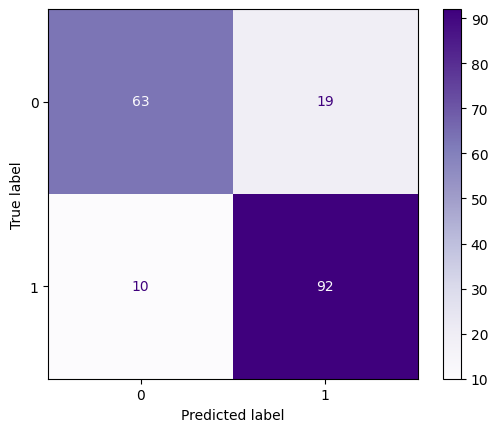

In [ ]:
cm  = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(cm).plot(cmap='Purples')

plt.show()

## 8. Conclusão

O melhor modelo foi o SVM com kernel RBF, C = 10 e gamma = 0,01. A acurácia média na validação cruzada foi de 82,70% e, no conjunto de teste, de 84,24% (contra 82,07% do SVM com parâmetros padrão). A proximidade entre os valores de validação e teste indica boa generalização, sem sinais de overfitting. O ajuste de hiperparâmetros trouxe uma melhora modesta, de cerca de 2 pontos percentuais em relação ao modelo base. Pela matriz de confusão, dos 82 pacientes sem doença, 63 foram classificados corretamente e 19 foram classificados como doentes (falsos positivos), o que resulta em recall de 76,8% para essa classe. Dos 102 pacientes com doença cardíaca, 92 foram identificados e 10 foram classificados como saudáveis (falsos negativos), o que resulta em recall de 90,2% para a classe com doença. No total, o modelo cometeu 29 erros em 184 previsões. Como os falsos negativos são o erro mais grave neste contexto, pois um paciente com doença deixa de ser identificado, o recall de 90,2% da classe positiva é a métrica mais relevante a destacar.

# **UCI Heart Disease Data - Modelos de Árvore de Decisão, Random Forest e Boosting**

## 1. Importando bibliotecas

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
import kagglehub
path = kagglehub.dataset_download("redwankarimsony/heart-disease-data")

import os

dcardiaca = pd.read_csv(os.path.join(path, 'heart_disease_uci.csv'))

print(dcardiaca.shape)

print(dcardiaca.head())

Using Colab cache for faster access to the 'heart-disease-data' dataset.
(920, 16)
   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  num  
0       fixed defect    0  
1             normal    2  
2  revers

## 2. Análise dos dados e limpeza

In [ ]:
print(dcardiaca.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB
None


In [ ]:
print('Dados nulos: ')
print(dcardiaca.isnull().sum())

Dados nulos: 
id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


In [ ]:
# a coluna 'id' é só um identificador do paciente e não ajuda o modelo, então é removida
dcardiaca = dcardiaca.drop(columns=['id'])

In [ ]:
print('Duplicados: ')
print(dcardiaca.duplicated().sum())

Duplicados: 
2


In [ ]:
dcardiaca = dcardiaca.drop_duplicates()

In [ ]:
# em trestbps (pressão) e chol (colesterol) o valor 0 é impossível: são valores ausentes disfarçados
print('Zeros em trestbps e chol: ')
print((dcardiaca[['trestbps', 'chol']] == 0).sum())

dcardiaca[['trestbps', 'chol']] = dcardiaca[['trestbps', 'chol']].mask(dcardiaca[['trestbps', 'chol']] == 0)

Zeros em trestbps e chol: 
trestbps      1
chol        172
dtype: int64


In [ ]:
# preenchimento dos dados nulos:
# mediana nas colunas numéricas contínuas (não é afetada por valores extremos)
# moda nas colunas de texto, verdadeiro/falso e de contagem (ca), pois é o valor mais frequente
colunas_mediana = ['trestbps', 'chol', 'thalch', 'oldpeak']
colunas_moda = ['fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

for col in colunas_mediana:
    dcardiaca[col] = dcardiaca[col].fillna(dcardiaca[col].median())

for col in colunas_moda:
    dcardiaca[col] = dcardiaca[col].fillna(dcardiaca[col].mode()[0])

print('Dados nulos após o preenchimento: ')
print(dcardiaca.isnull().sum())

Dados nulos após o preenchimento: 
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


/tmp/ipykernel_6044/984118661.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dcardiaca[col] = dcardiaca[col].fillna(dcardiaca[col].mode()[0])


In [ ]:
print(dcardiaca.shape)

print(dcardiaca.info())

(918, 15)
<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 0 to 919
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   dataset   918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  918 non-null    float64
 5   chol      918 non-null    float64
 6   fbs       918 non-null    bool   
 7   restecg   918 non-null    object 
 8   thalch    918 non-null    float64
 9   exang     918 non-null    bool   
 10  oldpeak   918 non-null    float64
 11  slope     918 non-null    object 
 12  ca        918 non-null    float64
 13  thal      918 non-null    object 
 14  num       918 non-null    int64  
dtypes: bool(2), float64(5), int64(2), object(6)
memory usage: 102.2+ KB
None


## 3. Transformação numérica

In [ ]:
alvo = 'num'

# a coluna 'num' vai de 0 (sem doença) a 4 (níveis de doença); aqui o alvo é binário: 0 = sem doença, 1 = com doença
dcardiaca[alvo] = (dcardiaca[alvo] > 0).astype(int)

# colunas de texto (sex, dataset, cp, restecg, slope, thal) e verdadeiro/falso (fbs, exang) viram números
for col in dcardiaca.select_dtypes(exclude=['number']).columns:

  le = LabelEncoder()
  dcardiaca[col] = le.fit_transform(dcardiaca[col])
  print(col, ':', list(le.classes_))

print(dcardiaca.dtypes)

sex : ['Female', 'Male']
dataset : ['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach']
cp : ['asymptomatic', 'atypical angina', 'non-anginal', 'typical angina']
fbs : [np.False_, np.True_]
restecg : ['lv hypertrophy', 'normal', 'st-t abnormality']
exang : [np.False_, np.True_]
slope : ['downsloping', 'flat', 'upsloping']
thal : ['fixed defect', 'normal', 'reversable defect']
age           int64
sex           int64
dataset       int64
cp            int64
trestbps    float64
chol        float64
fbs           int64
restecg       int64
thalch      float64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal          int64
num           int64
dtype: object


## 4. Divisão X e y, treino e teste

In [ ]:
X = dcardiaca.drop(columns=[alvo])

y = dcardiaca[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 5. Criação e treinamento dos modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado


## 6. Previsões nos dados de teste

In [ ]:
previsoes = {nome: modelo.predict(X_test) for nome, modelo in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:  ', y_pred)

Valores reais: 514    1
825    1
852    1
804    1
887    0
      ..
59     0
815    1
631    1
740    1
282    1
Name: num, Length: 184, dtype: int64
Árvore de Decisão:   [1 1 1 1 0 0 0 1 0 1 1 0 0 0 0 1 0 1 0 0 0 1 0 0 1 1 0 1 1 0 0 0 1 0 1 0 0
 1 0 0 1 1 1 0 1 1 1 0 1 0 0 1 0 0 1 0 1 0 0 0 1 1 0 1 0 1 0 1 0 0 0 0 0 1
 0 1 1 1 1 0 0 1 1 0 1 0 0 1 0 1 0 1 0 0 0 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0 1
 1 0 1 1 1 1 0 0 1 0 1 0 1 0 1 0 1 1 0 0 1 0 0 1 1 0 0 1 0 1 1 1 0 1 0 1 1
 0 1 1 0 0 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 0 1 0 0 0 0 0 1 1 1 1 1 1]
Random Forest:   [0 1 1 1 1 0 0 1 0 1 0 0 0 0 0 1 0 1 0 0 0 1 0 1 1 1 0 1 0 0 0 0 1 1 1 0 1
 1 0 0 1 1 1 0 1 1 1 0 0 1 0 0 0 0 1 0 1 0 0 0 0 1 0 1 0 1 0 1 0 0 1 1 0 1
 0 1 1 1 1 0 0 1 1 0 1 0 1 1 0 1 0 1 0 0 0 1 1 1 0 1 0 1 1 0 1 1 1 1 0 0 1
 0 0 1 1 1 1 0 0 1 0 1 1 1 0 1 1 1 1 0 0 1 0 0 1 1 1 0 1 1 1 1 1 0 1 1 1 0
 0 1 1 0 0 1 1 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 0 0 1 1 1 1 1 1]
Gradient Boosting:   [0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1 0 1 0 1 0

## 7. Avaliação e comparação

In [ ]:
nomes_classes = ['Sem doença (0)', 'Com doença (1)']

resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia,
                       'Precisão (classe 1)': precision_score(y_test, y_pred, zero_division=0),
                       'Recall (classe 1)': recall_score(y_test, y_pred),
                       'F1 (classe 1)': f1_score(y_test, y_pred)})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, target_names=nomes_classes, zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False).round(4)


Árvore de Decisão — Acurácia: 80.43%
                precision    recall  f1-score   support

Sem doença (0)       0.77      0.80      0.79        82
Com doença (1)       0.84      0.80      0.82       102

      accuracy                           0.80       184
     macro avg       0.80      0.80      0.80       184
  weighted avg       0.81      0.80      0.80       184


Random Forest — Acurácia: 80.98%
                precision    recall  f1-score   support

Sem doença (0)       0.80      0.77      0.78        82
Com doença (1)       0.82      0.84      0.83       102

      accuracy                           0.81       184
     macro avg       0.81      0.81      0.81       184
  weighted avg       0.81      0.81      0.81       184


Gradient Boosting — Acurácia: 80.98%
                precision    recall  f1-score   support

Sem doença (0)       0.81      0.74      0.78        82
Com doença (1)       0.81      0.86      0.83       102

      accuracy                           0

,Modelo,Acurácia,Precisão (classe 1),Recall (classe 1),F1 (classe 1)
1,Random Forest,0.8098,0.8190,0.8431,0.8309
2,Gradient Boosting,0.8098,0.8073,0.8627,0.8341
0,Árvore de Decisão,0.8043,0.8367,0.8039,0.8200


## 8. Matriz de confusão

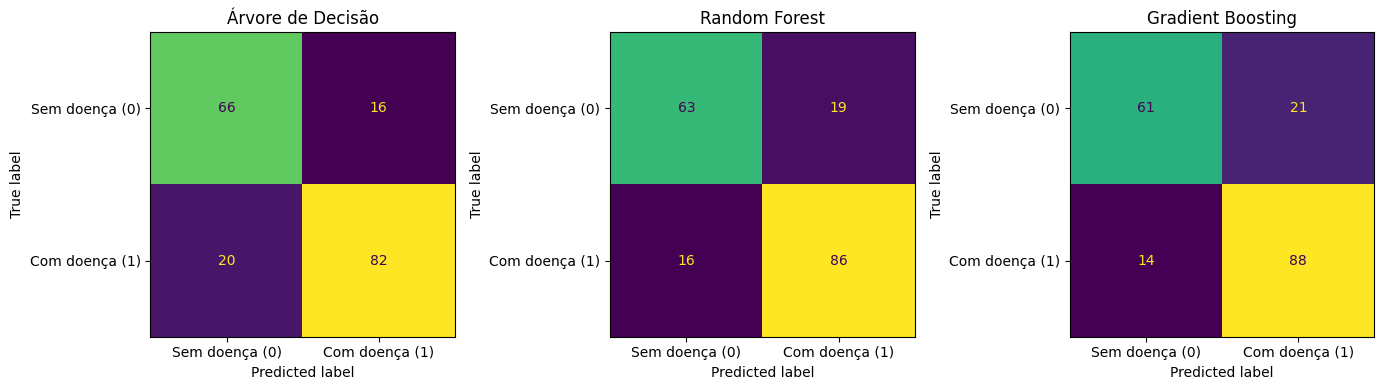

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        display_labels=nomes_classes, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

## 9. Conclusão

Foram comparados três modelos baseados em árvores: Árvore de Decisão, Random Forest e Gradient Boosting. O Random Forest e o Gradient Boosting empataram com a maior acurácia, 80,98% (149 acertos em 184 amostras), seguidos de perto pela Árvore de Decisão, com 80,43% (148 acertos). A diferença entre o primeiro e o último colocado é de apenas uma amostra.

A Árvore de Decisão teve o menor número de falsos positivos entre os três, com 16 pacientes sem doença classificados como doentes, mas também o maior número de falsos negativos: 20 pacientes com doença não foram identificados. Isso resultou em precisão de 0,84 e recall de 0,80 para a classe com doença. O Random Forest cometeu 19 falsos positivos e 16 falsos negativos (precisão de 0,82 e recall de 0,84). O Gradient Boosting cometeu 21 falsos positivos e 14 falsos negativos (precisão de 0,81 e recall de 0,86). Os ensembles, portanto, trocaram alguns falsos positivos por menos falsos negativos em relação à árvore única.

Em diagnóstico de doença cardíaca, o falso negativo é o erro mais grave, pois um paciente doente deixa de ser identificado. Por isso o recall da classe com doença é a métrica mais relevante, e o Gradient Boosting foi o melhor nesse critério, seguido pelo Random Forest e pela Árvore de Decisão. Ainda assim, as diferenças são pequenas: entre o Gradient Boosting e o Random Forest há apenas 2 falsos negativos, e a acurácia dos três modelos varia em uma amostra. Com um conjunto de teste de 184 amostras, não é possível afirmar com segurança que um modelo seja superior aos demais.

# **COMPARAÇÃO SVM x MODELOS BASEADOS EM ÁRVORES**

In [ ]:
# COMPARAÇÃO FINAL DOS MODELOS
# Reúne as previsões dos 4 modelos (SVM com GridSearch, Árvore de Decisão, Random Forest
# e Gradient Boosting) e calcula as mesmas métricas para todos, no mesmo conjunto de teste.
#
# O alvo (target) é binário. Considera-se a classe 1 como a classe positiva (com doença cardíaca).
# Para cada modelo, a matriz de confusão é separada em falsos positivos (sem doença previsto
# como com doença) e falsos negativos (com doença previsto como sem doença).
# Com isso são calculados: acurácia, total de erros, recall e precisão da classe 1.
#
# A tabela é ordenada pelo menor número de erros e, em caso de empate, pelo menor número
# de falsos negativos, que é o erro mais grave, pois um paciente com doença deixa de ser identificado.
# Obs.: o SVM passou por GridSearch; as árvores usam os parâmetros padrão.

previsoes_final = {'SVM (GridSearch)': grid.best_estimator_.predict(X_test), **previsoes}

linhas = []
for nome, y_pred in previsoes_final.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    linhas.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_test, y_pred),
        'Erros': fp + fn,
        'Falsos positivos': fp,
        'Falsos negativos': fn,
        'Recall (classe 1)': recall_score(y_test, y_pred),
        'Precisão (classe 1)': precision_score(y_test, y_pred, zero_division=0),
        'F1 (classe 1)': f1_score(y_test, y_pred),
    })

tabela = pd.DataFrame(linhas).sort_values(['Erros', 'Falsos negativos']).reset_index(drop=True)
tabela.round(4)

,Modelo,Acurácia,Erros,Falsos positivos,Falsos negativos,Recall (classe 1),Precisão (classe 1),F1 (classe 1)
0,SVM (GridSearch),0.8424,29,19,10,0.9020,0.8288,0.8638
1,Gradient Boosting,0.8098,35,21,14,0.8627,0.8073,0.8341
2,Random Forest,0.8098,35,19,16,0.8431,0.8190,0.8309
3,Árvore de Decisão,0.8043,36,16,20,0.8039,0.8367,0.8200


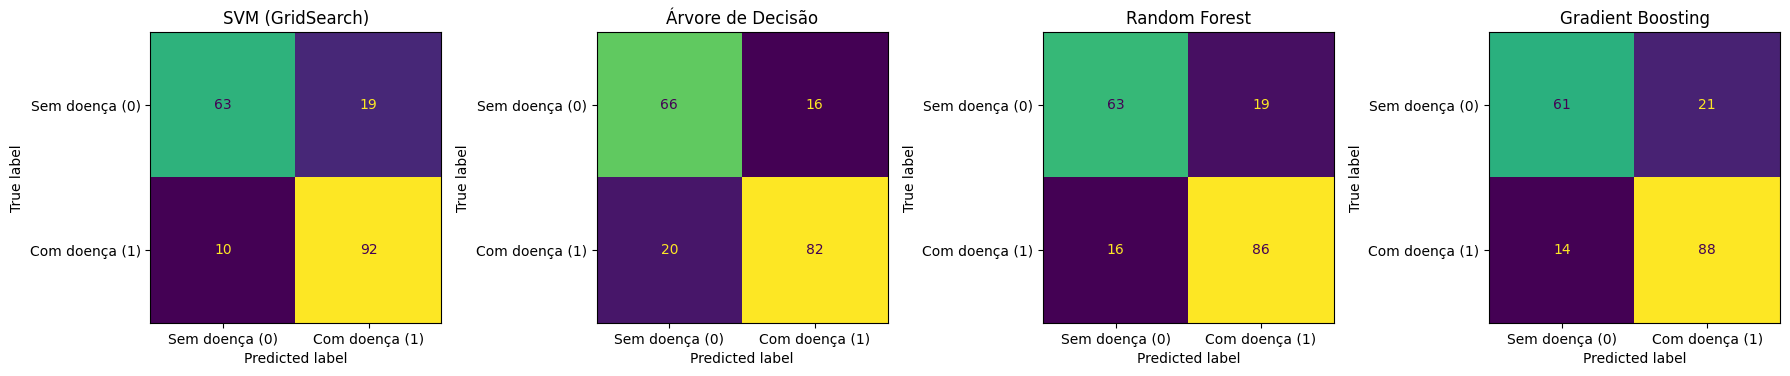

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nome, y_pred) in zip(axes, previsoes_final.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        display_labels=nomes_classes, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

Neste trabalho foram avaliados quatro classificadores para prever a presença de doença cardíaca a partir de 14 variáveis clínicas de 920 pacientes (como idade, sexo, tipo de dor no peito, pressão arterial e colesterol): SVM com ajuste de hiperparâmetros por GridSearch, Random Forest, Gradient Boosting e Árvore de Decisão. Todos foram avaliados no mesmo conjunto de teste, com 184 amostras (82 sem doença e 102 com doença), o que permite uma comparação direta.

Desempenho geral. O SVM com kernel RBF, C = 10 e gamma = 0,01 obteve a melhor acurácia (84,24%), com 29 erros em 184 amostras. Em seguida vieram o Random Forest e o Gradient Boosting, empatados com 80,98% (35 erros cada), e a Árvore de Decisão, com 80,43% (36 erros). A acurácia média do SVM na validação cruzada foi de 82,70%, próxima à do teste, o que indica boa capacidade de generalização e ausência de sinais de overfitting. O desempenho geral dos modelos é moderado, e a diferença entre os três modelos de árvores é de apenas uma amostra.

Modelos baseados em árvores. A Árvore de Decisão teve o menor número de falsos positivos entre os modelos (16), mas também o maior número de falsos negativos (20), com precisão de 0,84 e recall de 0,80 na classe com doença. Os ensembles não trouxeram ganho expressivo de acurácia, reduzindo os erros de 36 para 35, mas mudaram o equilíbrio entre os tipos de erro: o Random Forest cometeu 19 falsos positivos e 16 falsos negativos, e o Gradient Boosting, 21 falsos positivos e 14 falsos negativos. Em outras palavras, os ensembles passaram a identificar mais pacientes doentes, ao custo de classificar mais pacientes saudáveis como doentes.

Análise por tipo de erro. Em diagnóstico médico, os dois tipos de erro têm custos diferentes. O falso positivo (paciente sem doença classificado como doente) gera exames adicionais e ansiedade, mas é corrigível. O falso negativo (paciente com doença classificado como saudável) é o mais grave, pois pode atrasar o tratamento. Por isso o recall da classe com doença é a métrica mais importante. O SVM teve o melhor recall (90,2%, com 10 falsos negativos), seguido pelo Gradient Boosting (86,3%, com 14), pelo Random Forest (84,3%, com 16) e pela Árvore de Decisão (80,4%, com 20). Já a precisão ficou entre 80,7% (Gradient Boosting) e 83,7% (Árvore de Decisão), ou seja, nenhum modelo teve precisão perfeita: de 16% a 19% dos pacientes classificados como doentes na verdade não tinham a doença.

SVM versus ensembles. O SVM superou os modelos de árvores tanto em acurácia quanto em recall, e foi o único modelo a passar por ajuste de hiperparâmetros, o que pode explicar parte da vantagem. O GridSearch selecionou o kernel RBF entre os quatro testados, mas, como o notebook não compara a acurácia de cada kernel separadamente, não é possível concluir, apenas com esses resultados, que a relação entre as variáveis e o diagnóstico seja não linear. Vale lembrar também que o conjunto mistura variáveis numéricas e categóricas; as categóricas foram convertidas em números com LabelEncoder, o que impõe uma ordem artificial entre as categorias e pode afetar mais o SVM, que depende de distâncias, do que os modelos de árvores.

Limitações. O conjunto de teste é pequeno, e cada erro equivale a cerca de 0,5 ponto percentual de acurácia. A vantagem do SVM sobre o Random Forest e o Gradient Boosting é de 6 erros (cerca de 3 pontos percentuais), e sobre a Árvore de Decisão, de 7 erros, o que sugere uma superioridade do SVM, mas uma única divisão treino-teste não basta para confirmá-la. Além disso, o SVM passou por GridSearch, enquanto os modelos de árvores foram avaliados com parâmetros padrão, o que favorece o SVM. Há ainda limitações nos dados: variáveis com muitos valores ausentes (cerca de dois terços em ca e mais da metade em thal) foram preenchidas com a moda, o que pode distorcer as relações com o diagnóstico; o alvo foi simplificado para presença ou ausência de doença; e o conjunto reúne pacientes de diferentes instituições. Para uma análise mais robusta, seria recomendável avaliar todos os modelos com validação cruzada repetida e aplicar o mesmo ajuste de hiperparâmetros aos modelos de árvores.

Conclusão. O SVM com GridSearch obteve o melhor resultado, com a maior acurácia (84,24%) e o maior recall para a classe com doença (90,2%), seguido pelos ensembles Gradient Boosting e Random Forest, que ficaram praticamente empatados, e pela Árvore de Decisão. As diferenças entre os modelos de árvores são mínimas, e nenhum modelo alcançou desempenho alto o bastante para uso clínico isolado, sendo o recall de 90,2% do SVM o resultado mais promissor para triagem.

# **Heart Disease Dataset com SVM, 4 kernels, C e gamma**

## 1. Fazendo as importações e visualizando o dataset

In [ ]:
import kagglehub

path = kagglehub.dataset_download("mfarhaannazirkhan/heart-dataset")

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import os

hdisease = pd.read_csv(os.path.join(path, 'cleaned_merged_heart_dataset.csv'))

print(hdisease.shape)
print(hdisease.head())

Using Colab cache for faster access to the 'heart-dataset' dataset.
(1888, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalachh  exang  oldpeak  \
0   63    1   3       145   233    1        0       150      0      2.3   
1   37    1   2       130   250    0        1       187      0      3.5   
2   41    0   1       130   204    0        0       172      0      1.4   
3   56    1   1       120   236    0        1       178      0      0.8   
4   57    0   0       120   354    0        1       163      1      0.6   

   slope  ca  thal  target  
0      0   0     1       1  
1      0   0     2       1  
2      2   0     2       1  
3      2   0     2       1  
4      2   0     2       1  


## 2. Tratando os dados

In [ ]:
print(hdisease.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1888 entries, 0 to 1887
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1888 non-null   int64  
 1   sex       1888 non-null   int64  
 2   cp        1888 non-null   int64  
 3   trestbps  1888 non-null   int64  
 4   chol      1888 non-null   int64  
 5   fbs       1888 non-null   int64  
 6   restecg   1888 non-null   int64  
 7   thalachh  1888 non-null   int64  
 8   exang     1888 non-null   int64  
 9   oldpeak   1888 non-null   float64
 10  slope     1888 non-null   int64  
 11  ca        1888 non-null   int64  
 12  thal      1888 non-null   int64  
 13  target    1888 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 206.6 KB
None


In [ ]:
print('Dados nulos: ')
print(hdisease.isnull().sum())

Dados nulos: 
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalachh    0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [ ]:
print('Duplicados: ')
print(hdisease.duplicated().sum())

Duplicados: 
1286


In [ ]:
hdisease = hdisease.dropna()

In [ ]:
hdisease = hdisease.drop_duplicates()

In [ ]:
print(hdisease.shape)

print(hdisease.info())

(602, 14)
<class 'pandas.core.frame.DataFrame'>
Index: 602 entries, 0 to 1887
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       602 non-null    int64  
 1   sex       602 non-null    int64  
 2   cp        602 non-null    int64  
 3   trestbps  602 non-null    int64  
 4   chol      602 non-null    int64  
 5   fbs       602 non-null    int64  
 6   restecg   602 non-null    int64  
 7   thalachh  602 non-null    int64  
 8   exang     602 non-null    int64  
 9   oldpeak   602 non-null    float64
 10  slope     602 non-null    int64  
 11  ca        602 non-null    int64  
 12  thal      602 non-null    int64  
 13  target    602 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 70.5 KB
None


## 3. Definindo um alvo e tratando dados não numéricos

In [ ]:
alvo = 'target'

for col in hdisease.select_dtypes(include=['object', 'category']).columns:

  le = LabelEncoder()
  hdisease[col] = le.fit_transform(hdisease[col])
  print(col, ':', list(le.classes_))

print(hdisease.dtypes)


age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalachh      int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


## 4. Dividindo os dados em X e y

In [ ]:
X = hdisease.drop(columns=[alvo])

y = hdisease[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

## 5. SVM com GridSearch e 4 kernels, C e gamma

In [ ]:
model = Pipeline([('scaler', StandardScaler()), ('svm', SVC())])

param_grid = {
    'svm__kernel': ['linear', 'rbf', 'poly', 'sigmoid'],

    'svm__C': [0.1, 1, 10, 100],

    'svm__gamma': [0.001, 0.01, 0.1, 1]
}

grid = GridSearchCV (model, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)

grid.fit(X_train, y_train)

print(grid.best_params_)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
{'svm__C': 1, 'svm__gamma': 0.1, 'svm__kernel': 'rbf'}


## 6. Resultados

In [ ]:
# SVM base: cria um pipeline novo e TREINA antes de prever
svm_base = Pipeline([('scaler', StandardScaler()), ('svm', SVC())])
svm_base.fit(X_train, y_train)
acc_base = accuracy_score(y_test, svm_base.predict(X_test))

# GridSearch: já foi treinado no grid.fit()
y_pred = grid.best_estimator_.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print('Modelo: SVM')
print('Melhores parametros: ', grid.best_params_)
print('Acuracia na validação cruzada: ', grid.best_score_)
print('Acuracia do SVM (base): ', acc_base)
print('Acuracia do GridSearch: ', accuracy)

Modelo: SVM
Melhores parametros:  {'svm__C': 1, 'svm__gamma': 0.1, 'svm__kernel': 'rbf'}
Acuracia na validação cruzada:  0.7568943298969072
Acuracia do SVM (base):  0.768595041322314
Acuracia do GridSearch:  0.7933884297520661


## 7. Matriz de confusão

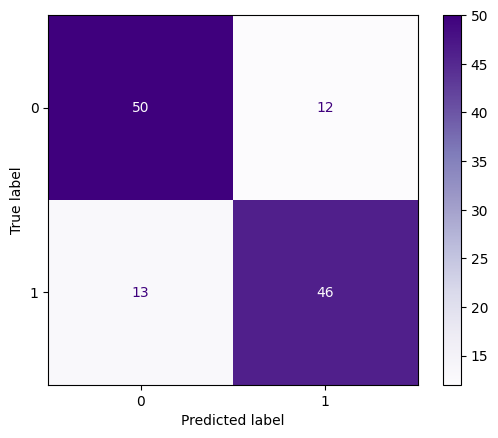

In [ ]:
cm  = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(cm).plot(cmap='Purples')

plt.show()

## 8. Resultados

O melhor modelo foi o SVM com kernel RBF, C = 1 e gamma = 0,1. A acurácia média na validação cruzada foi de 75,69% e, no conjunto de teste, de 79,34% (contra 76,86% do SVM com parâmetros padrão). A acurácia de teste ficou cerca de 3,6 pontos acima da de validação, o que indica que o modelo generaliza bem, sem sinais de overfitting. Pela matriz de confusão, o modelo acertou 96 das 121 amostras de teste. Dos 62 casos de menor risco (0), 50 foram identificados (recall de 80,6%); dos 59 de maior risco (1), 46 (recall de 78,0%). Dos 25 erros, 12 foram falsos positivos (casos de menor risco previstos como maior risco) e 13 foram falsos negativos (casos de maior risco previstos como menor risco), uma divisão bem equilibrada. A precisão foi de 79,3% para a classe de maior risco (46 de 58 previsões corretas) e de 79,4% para a de menor risco (50 de 63). Como o falso negativo é o erro mais grave, pois deixa de identificar um paciente com maior chance de ataque cardíaco, o resultado ainda deixa espaço para melhorias.

# **Heart Disese Dataset com Arvore de decisão, Random Forest e Boosting**

## 1. Importando bibliotecas

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score)
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
import kagglehub

path = kagglehub.dataset_download("mfarhaannazirkhan/heart-dataset")

import os

hdisease = pd.read_csv(os.path.join(path, 'cleaned_merged_heart_dataset.csv'))

print(hdisease.shape)
print(hdisease.head())

Using Colab cache for faster access to the 'heart-dataset' dataset.
(1888, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalachh  exang  oldpeak  \
0   63    1   3       145   233    1        0       150      0      2.3   
1   37    1   2       130   250    0        1       187      0      3.5   
2   41    0   1       130   204    0        0       172      0      1.4   
3   56    1   1       120   236    0        1       178      0      0.8   
4   57    0   0       120   354    0        1       163      1      0.6   

   slope  ca  thal  target  
0      0   0     1       1  
1      0   0     2       1  
2      2   0     2       1  
3      2   0     2       1  
4      2   0     2       1  


## 2. Análise dos dados e limpeza

In [ ]:
print(hdisease.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1888 entries, 0 to 1887
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1888 non-null   int64  
 1   sex       1888 non-null   int64  
 2   cp        1888 non-null   int64  
 3   trestbps  1888 non-null   int64  
 4   chol      1888 non-null   int64  
 5   fbs       1888 non-null   int64  
 6   restecg   1888 non-null   int64  
 7   thalachh  1888 non-null   int64  
 8   exang     1888 non-null   int64  
 9   oldpeak   1888 non-null   float64
 10  slope     1888 non-null   int64  
 11  ca        1888 non-null   int64  
 12  thal      1888 non-null   int64  
 13  target    1888 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 206.6 KB
None


In [ ]:
print('Dados nulos: ')
print(hdisease.isnull().sum())

Dados nulos: 
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalachh    0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [ ]:
print('Duplicados: ')
print(hdisease.duplicated().sum())

Duplicados: 
1286


In [ ]:
#hdisease = hdisease.drop(columns=["id"]) não existe nenhuma coluna de identificação
hdisease = hdisease.drop_duplicates()
hdisease = hdisease.dropna()
print(hdisease.shape)

(602, 14)


## 3. Transformação numérica

In [ ]:
alvo = 'target'

for col in hdisease.select_dtypes(include=['object', 'category']).columns:

  le = LabelEncoder()
  hdisease[col] = le.fit_transform(hdisease[col])
  print(col, ':', list(le.classes_))

print(hdisease.dtypes)

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalachh      int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


## 4. Divisão X e y, treino e teste

In [ ]:
X = hdisease.drop(columns=[alvo])

y = hdisease[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 5. Criação e treinamento dos modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado


## 6. Previsões nos dados de teste

In [ ]:
previsoes = {nome: modelo.predict(X_test) for nome, modelo in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:  ', y_pred)

Valores reais: 223     0
1568    0
1489    1
1531    1
1580    0
       ..
1886    0
34      1
1342    1
53      1
1381    0
Name: target, Length: 121, dtype: int64
Árvore de Decisão:   [1 0 0 1 0 0 1 0 1 0 0 0 1 1 1 0 1 0 0 0 1 1 1 0 1 0 1 0 1 1 1 1 0 1 1 1 0
 1 0 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 1 1 0 1 1 0 0 1 0 1 1 0 0 1 1 0 1 1 0 1
 0 1 1 0 1 1 0 0 0 0 1 1 0 0 1 1 1 1 0 0 1 0 1 0 1 0 0 0 0 1 0 0 0 0 1 0 0
 0 1 0 0 1 1 1 0 0 0]
Random Forest:   [0 0 0 1 0 0 0 0 1 0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 1 1 0 0 1 1 1 0 1 0 1 0
 1 1 0 0 0 1 0 0 1 0 0 0 1 0 0 0 1 1 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 1 1 0 1
 1 0 1 0 1 1 0 0 0 0 0 0 0 0 0 1 0 1 1 0 1 1 1 0 0 0 0 1 0 1 1 0 0 1 1 0 0
 1 1 0 0 1 0 1 0 1 0]
Gradient Boosting:   [0 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 1 0 1 1 1 0 0 1 1 1 0 1 0 1 0
 1 1 0 0 0 1 0 0 1 1 0 0 1 0 0 0 1 0 1 1 1 1 0 0 1 0 1 1 0 0 1 1 1 1 1 0 1
 1 0 1 0 1 1 0 0 0 0 0 0 0 0 0 1 0 1 0 1 1 1 1 0 0 0 0 1 0 1 1 0 0 1 1 0 0
 1 1 0 0 1 1 1 0 1 0]


## 7. Avaliação e comparação

In [ ]:
nomes_classes = ['Menor risco (0)', 'Maior risco (1)']

resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia,
                       'Precisão (classe 1)': precision_score(y_test, y_pred, zero_division=0),
                       'Recall (classe 1)': recall_score(y_test, y_pred),
                       'F1 (classe 1)': f1_score(y_test, y_pred)})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, target_names=nomes_classes, zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False).round(4)


Árvore de Decisão — Acurácia: 64.46%
                 precision    recall  f1-score   support

Menor risco (0)       0.65      0.68      0.66        62
Maior risco (1)       0.64      0.61      0.63        59

       accuracy                           0.64       121
      macro avg       0.64      0.64      0.64       121
   weighted avg       0.64      0.64      0.64       121


Random Forest — Acurácia: 80.99%
                 precision    recall  f1-score   support

Menor risco (0)       0.79      0.85      0.82        62
Maior risco (1)       0.83      0.76      0.80        59

       accuracy                           0.81       121
      macro avg       0.81      0.81      0.81       121
   weighted avg       0.81      0.81      0.81       121


Gradient Boosting — Acurácia: 80.17%
                 precision    recall  f1-score   support

Menor risco (0)       0.79      0.84      0.81        62
Maior risco (1)       0.82      0.76      0.79        59

       accuracy            

,Modelo,Acurácia,Precisão (classe 1),Recall (classe 1),F1 (classe 1)
1,Random Forest,0.8099,0.8333,0.7627,0.7965
2,Gradient Boosting,0.8017,0.8182,0.7627,0.7895
0,Árvore de Decisão,0.6446,0.6429,0.6102,0.6261


## 8. Matriz de confusão

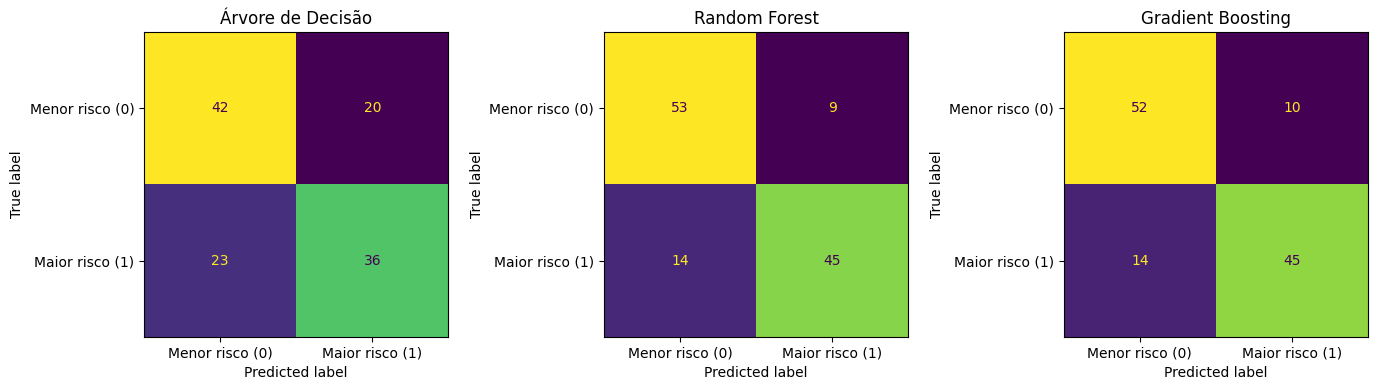

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        display_labels=nomes_classes, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

## 9. Conclusão

Foram comparados três modelos baseados em árvores: Árvore de Decisão, Random Forest e Gradient Boosting. O Random Forest teve o melhor desempenho, com acurácia de 80,99% (98 acertos em 121 amostras), seguido pelo Gradient Boosting, com 80,17% (97 acertos), e pela Árvore de Decisão, com 64,46% (78 acertos).

A Árvore de Decisão foi o modelo mais fraco, com 43 erros distribuídos entre as duas classes: 20 casos de menor risco foram classificados como maior risco (falsos positivos) e 23 de maior risco foram classificados como menor risco (falsos negativos). O recall foi de 67,7% para a classe de menor risco e de 61,0% para a de maior risco, e o F1 médio ficou em 0,64. Esse resultado é esperado, pois uma única árvore tende a se ajustar demais aos dados de treino e generaliza pior que os métodos de ensemble.

O Random Forest e o Gradient Boosting tiveram 23 e 24 erros, respectivamente, e os dois deixaram de identificar 14 casos de maior risco (recall de 76,3% nessa classe). A diferença entre eles está nos falsos positivos: o Random Forest errou 9 casos de menor risco, contra 10 do Gradient Boosting, o que deu a ele precisão de 83,3% na classe de maior risco, contra 81,8%, e recall de 85,5% na classe de menor risco, contra 83,9%. O F1 médio foi de 0,81 para o Random Forest e de 0,80 para o Gradient Boosting.

Neste problema, o erro mais grave é classificar um paciente de maior risco de ataque cardíaco como de menor risco, pois o caso que mais precisa de atenção passa despercebido. Por isso o recall da classe de maior risco é a métrica mais relevante. Nesse critério, o Random Forest e o Gradient Boosting empataram, com 14 falsos negativos cada, contra 23 da Árvore de Decisão. Ainda assim, o conjunto de teste tem 121 amostras, e cada erro equivale a cerca de 0,83 ponto percentual. A vantagem do Random Forest sobre o Gradient Boosting é de uma única amostra, o que não permite afirmar com segurança que ele seja superior.

# **COMPARAÇÃO SVM x MODELOS BASEADOS EM ÁRVORES**

In [ ]:
# COMPARAÇÃO FINAL DOS MODELOS
# Reúne as previsões dos 4 modelos (SVM com GridSearch, Árvore de Decisão, Random Forest
# e Gradient Boosting) e calcula as mesmas métricas para todos, no mesmo conjunto de teste.
#
# O alvo (target) é binário. Considera-se a classe 1 como a classe positiva (maior risco de ataque cardíaco).
# Para cada modelo, a matriz de confusão é separada em falsos positivos (menor risco previsto
# como maior risco) e falsos negativos (maior risco previsto como menor risco).
# Com isso são calculados: acurácia, total de erros, recall e precisão da classe 1.
#
# A tabela é ordenada pelo menor número de erros e, em caso de empate, pelo menor número
# de falsos negativos, que é o erro mais grave, pois um paciente de maior risco deixa de ser identificado.
# Obs.: o SVM passou por GridSearch; as árvores usam os parâmetros padrão.

previsoes_final = {'SVM (GridSearch)': grid.best_estimator_.predict(X_test), **previsoes}

linhas = []
for nome, y_pred in previsoes_final.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    linhas.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_test, y_pred),
        'Erros': fp + fn,
        'Falsos positivos': fp,
        'Falsos negativos': fn,
        'Recall (classe 1)': recall_score(y_test, y_pred),
        'Precisão (classe 1)': precision_score(y_test, y_pred, zero_division=0),
        'F1 (classe 1)': f1_score(y_test, y_pred),
    })

tabela = pd.DataFrame(linhas).sort_values(['Erros', 'Falsos negativos']).reset_index(drop=True)
tabela.round(4)

,Modelo,Acurácia,Erros,Falsos positivos,Falsos negativos,Recall (classe 1),Precisão (classe 1),F1 (classe 1)
0,Random Forest,0.8099,23,9,14,0.7627,0.8333,0.7965
1,Gradient Boosting,0.8017,24,10,14,0.7627,0.8182,0.7895
2,SVM (GridSearch),0.7934,25,12,13,0.7797,0.7931,0.7863
3,Árvore de Decisão,0.6446,43,20,23,0.6102,0.6429,0.6261


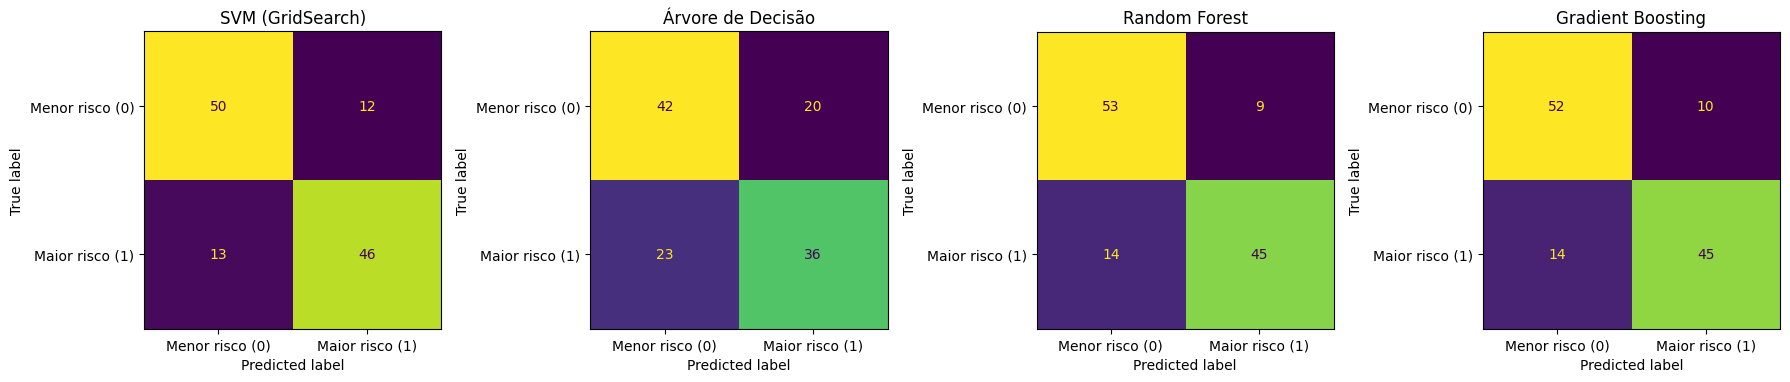

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nome, y_pred) in zip(axes, previsoes_final.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        display_labels=nomes_classes, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

Neste trabalho foram avaliados quatro classificadores para prever o risco de ataque cardíaco de pacientes (menor ou maior risco) a partir de 13 variáveis clínicas numéricas: SVM com ajuste de hiperparâmetros por GridSearch, Árvore de Decisão, Random Forest e Gradient Boosting. Todos foram avaliados no mesmo conjunto de teste, com 121 amostras (62 de menor risco e 59 de maior risco), o que permite uma comparação direta.

Desempenho geral. O Random Forest obteve a melhor acurácia (80,99%, com 23 erros), seguido pelo Gradient Boosting (80,17%, 24 erros), pelo SVM com kernel RBF, C = 1 e gamma = 0,1 (79,34%, 25 erros) e pela Árvore de Decisão (64,46%, 43 erros). O F1 médio foi de 0,81 para o Random Forest, 0,80 para o Gradient Boosting, 0,79 para o SVM e 0,64 para a Árvore de Decisão. A acurácia do SVM na validação cruzada (75,69%) ficou cerca de 3,6 pontos abaixo da do teste (79,34%), o que indica que o modelo generaliza bem, sem sinais de overfitting.

Modelos baseados em árvores. A Árvore de Decisão foi a de pior desempenho, com erros nas duas classes (20 falsos positivos e 23 falsos negativos). Os métodos de ensemble corrigiram esse problema ao combinar várias árvores: o Random Forest, que faz a média de árvores independentes, reduziu os erros de 43 para 23, e o Gradient Boosting, que treina árvores em sequência corrigindo os erros das anteriores, reduziu para 24.

Análise por tipo de erro. Os erros não têm o mesmo peso. O falso negativo (paciente de maior risco classificado como de menor risco) é o mais grave, pois deixa de identificar quem mais precisa de atenção, enquanto o falso positivo gera exames adicionais, mas é corrigível. Nesse critério, o SVM deixou passar 13 casos de maior risco (recall de 78,0%), o Random Forest e o Gradient Boosting 14 cada (76,3%) e a Árvore de Decisão 23 (61,0%). A diferença entre os três primeiros é de apenas uma amostra, então ficaram praticamente empatados. Nos falsos positivos, o Random Forest foi o que menos errou, com 9, seguido pelo Gradient Boosting (10), pelo SVM (12) e pela Árvore de Decisão (20), o que deu ao Random Forest a maior precisão na classe de maior risco (83,3%, contra 81,8%, 79,3% e 64,3%, respectivamente).

SVM versus ensembles. O SVM, mesmo com ajuste, não superou o Random Forest nem o Gradient Boosting com parâmetros padrão, embora tenha ficado muito próximo deles. O ganho do GridSearch sobre o SVM padrão foi de 3 amostras (de 76,86% para 79,34%). O kernel RBF foi o escolhido entre os quatro testados, e o melhor C (1) e o melhor gamma (0,1) ficaram no interior da grade, o que reduz a chance de que um valor melhor tenha ficado fora dela. Ainda assim, sem os resultados dos demais kernels, não é possível concluir que a relação entre as variáveis e o risco seja fortemente não linear.

Limitações. O conjunto de teste é pequeno, e cada erro equivale a cerca de 0,83 ponto percentual de acurácia. A diferença entre o Random Forest (23 erros) e o SVM (25 erros) é de apenas duas amostras, e entre o Random Forest e o Gradient Boosting, de uma, portanto não permitem afirmar que um seja superior; já a diferença para a Árvore de Decisão (43 erros) é expressiva. Além disso, o SVM passou por GridSearch, enquanto as árvores usaram parâmetros padrão, o que favorece o SVM na comparação. O conjunto original tinha 1.286 registros duplicados, que foram removidos, restando 602 amostras, o que também limita a robustez dos resultados. Para uma análise mais robusta, seria recomendável avaliar todos os modelos com validação cruzada repetida e aplicar o mesmo ajuste de hiperparâmetros às árvores.

Conclusão. O Random Forest, o Gradient Boosting e o SVM tiveram desempenho praticamente igual (entre 79% e 81% de acurácia), com leve vantagem do Random Forest em acurácia e em precisão e do SVM no recall da classe de maior risco. Os três ficaram muito à frente da Árvore de Decisão individual. Nenhum modelo passou de 81% de acurácia, então cerca de 1 em cada 5 pacientes ainda é classificado na categoria de risco errada, o que indica desempenho moderado.

# **Student Stress Factors (Prova B) com Modelos SVM, 4 kernels, C e gamma**

## 1. Fazendo as importações e visualizando o dataset

In [ ]:
import kagglehub
path = kagglehub.dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


import os
student = pd.read_csv(os.path.join(path, 'StressLevelDataset.csv'))

print(student.shape)
print(student.head())

Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.
(1100, 21)
   anxiety_level  self_esteem  mental_health_history  depression  headache  \
0             14           20                      0          11         2   
1             15            8                      1          15         5   
2             12           18                      1          14         2   
3             16           12                      1          15         4   
4             16           28                      0           7         2   

   blood_pressure  sleep_quality  breathing_problem  noise_level  \
0               1              2                  4            2   
1               3              1                  4            3   
2               1              2                  2            2   
3               3              1                  3            4   
4               3              5                  1            3   

   living

## 2. Tratando os dados

In [ ]:
print(student.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load                    110

In [ ]:
print('Dados nulos: ')
print(student.isnull(). sum())

Dados nulos: 
anxiety_level                   0
self_esteem                     0
mental_health_history           0
depression                      0
headache                        0
blood_pressure                  0
sleep_quality                   0
breathing_problem               0
noise_level                     0
living_conditions               0
safety                          0
basic_needs                     0
academic_performance            0
study_load                      0
teacher_student_relationship    0
future_career_concerns          0
social_support                  0
peer_pressure                   0
extracurricular_activities      0
bullying                        0
stress_level                    0
dtype: int64


In [ ]:
print ('Duplicados: ')
print(student.duplicated().sum())

Duplicados: 
0


In [ ]:
# student = student.drop(columns=['id']) não foi necessário pois não tinha coluna 'id' ou qualquer oura similar

In [ ]:
# student = student.dropna() não foi necessário pois não tinha dados nulos

In [ ]:
# student = student.drop_duplicates() não foi necessário pois não tinha dados duplicados

In [ ]:
print(student.shape)

(1100, 21)


In [ ]:
print(student.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load                    110

## 3. Definindo um alvo e tratando dados não numéricos

In [ ]:
alvo = 'stress_level'
#esse laço for não era necessário, mas decidi manter pois é essencial tratar dados não-numéricos, já que o modelo so trabalha com dados numéricos.
for col in student.select_dtypes(include=['object', 'category']).columns:
  le = LabelEncoder()
  student[col] = le.fit_transform(student[col])
  print(col, ':', list(le.classes_)) #esse so funciona se for do tipo str, como ele ja era numerico, não roda

print(student.dtypes)

anxiety_level                   int64
self_esteem                     int64
mental_health_history           int64
depression                      int64
headache                        int64
blood_pressure                  int64
sleep_quality                   int64
breathing_problem               int64
noise_level                     int64
living_conditions               int64
safety                          int64
basic_needs                     int64
academic_performance            int64
study_load                      int64
teacher_student_relationship    int64
future_career_concerns          int64
social_support                  int64
peer_pressure                   int64
extracurricular_activities      int64
bullying                        int64
stress_level                    int64
dtype: object


## 4. Dividindo os dados em X e y

In [ ]:
X = student.drop(columns=[alvo])

y = student[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

## 5. SVM com GridSearch e 4 kernels, C e gamma

In [ ]:
model = Pipeline([('scaler', StandardScaler()), ('svm', SVC())])

param_grid = {
    'svm__kernel': ['linear', 'rbf', 'sigmoid', 'poly'],

    'svm__C': [0.1, 1, 10, 100],

    'svm__gamma': [0.001, 0.01, 0.1, 1]
}

grid = GridSearchCV(model, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)

grid.fit(X_train, y_train)

print(grid.best_params_)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
{'svm__C': 0.1, 'svm__gamma': 0.1, 'svm__kernel': 'sigmoid'}


## 6. Resultados

In [ ]:
print('Modelo: SVM')

svm_base = Pipeline([('scaler', StandardScaler()), ('svm', SVC())]) # cria um svm base, parametros padrões para servir de comparação
svm_base.fit(X_train, y_train) #treina o modelo base

acc_base = accuracy_score(y_test, svm_base.predict(X_test)) # calcula a acuracia do MODELO base nos dados de teste

y_pred = grid.best_estimator_.predict(X_test) # faz a previsão do teste com o melhor modelo encontrado pelo GridSearch

accuracy = accuracy_score(y_test, y_pred) # calcula a acuracia desse modelo no teste

print('Melhores parametros: ', grid.best_params_)
print('Acuracia na validação cruzada: ', grid.best_score_)
print('Acuracia do SVM(base): ', acc_base)
print('Acuracia do GridSearch: ', accuracy) # acuracia do modelo otimizado no teste

Modelo: SVM
Melhores parametros:  {'svm__C': 0.1, 'svm__gamma': 0.1, 'svm__kernel': 'sigmoid'}
Acuracia na validação cruzada:  0.8863636363636364
Acuracia do SVM(base):  0.8772727272727273
Acuracia do GridSearch:  0.8863636363636364


## 7. Matriz de Confusão

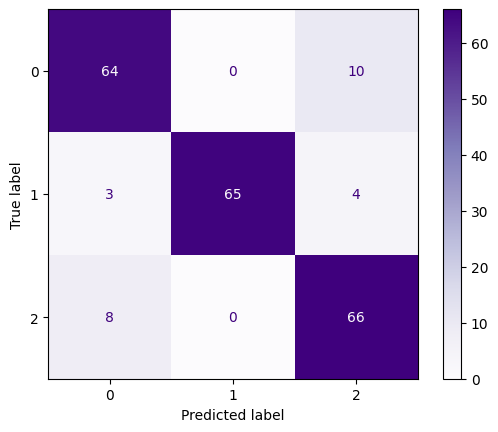

In [ ]:
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(cm).plot(cmap='Purples')

plt.show()

## 8. Conclusão

O melhor modelo foi o SVM com kernel sigmoid, C = 0,1 e gamma = 0,1. A acurácia média na validação cruzada foi de 88,64% e, no conjunto de teste, de 88,64% (contra 87,73% do SVM com parâmetros padrão). A proximidade entre os valores de validação e teste indica boa generalização, sem sinais de overfitting. Pela matriz de confusão, o modelo acertou 195 das 220 amostras de teste. Dos 74 casos de estresse baixo (0), 64 foram identificados (recall de 86,5%); dos 72 de estresse médio (1), 65 (90,3%); e dos 74 de estresse alto (2), 66 (89,2%). Dos 25 erros, 18 ocorreram entre as classes 0 e 2 (10 casos de baixo previstos como alto e 8 de alto previstos como baixo), enquanto a classe média nunca foi confundida com as demais na previsão: todas as 65 previsões de nível médio estavam corretas (precisão de 100%), e seus 7 erros foram casos médios previstos como baixo (3) ou alto (4).

# **Student Stress Factors (Prova B) com Arvore de decisão, Random Forest e Boosting**

## 1. Importando bibliotecas

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score)
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
import kagglehub
path = kagglehub.dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")

import os

student = pd.read_csv(os.path.join(path, 'StressLevelDataset.csv'))

print(student.shape)

print(student.head())

Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.
(1100, 21)
   anxiety_level  self_esteem  mental_health_history  depression  headache  \
0             14           20                      0          11         2   
1             15            8                      1          15         5   
2             12           18                      1          14         2   
3             16           12                      1          15         4   
4             16           28                      0           7         2   

   blood_pressure  sleep_quality  breathing_problem  noise_level  \
0               1              2                  4            2   
1               3              1                  4            3   
2               1              2                  2            2   
3               3              1                  3            4   
4               3              5                  1            3   

   living

## 2. Análise dos dados e limpeza

In [ ]:
print(student.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load                    110

In [ ]:
print('Dados nulos: ')
print(student.isnull().sum())

Dados nulos: 
anxiety_level                   0
self_esteem                     0
mental_health_history           0
depression                      0
headache                        0
blood_pressure                  0
sleep_quality                   0
breathing_problem               0
noise_level                     0
living_conditions               0
safety                          0
basic_needs                     0
academic_performance            0
study_load                      0
teacher_student_relationship    0
future_career_concerns          0
social_support                  0
peer_pressure                   0
extracurricular_activities      0
bullying                        0
stress_level                    0
dtype: int64


In [ ]:
print('Duplicados: ')
print(student.duplicated().sum())

Duplicados: 
0


In [ ]:
#student = student.drop(columns=["id"]) não existe nenhuma coluna de identificação
student = student.drop_duplicates()
student = student.dropna()
print(student.shape)

(1100, 21)


## 3. Transformação numérica

In [ ]:
alvo = 'stress_level'

for col in student.select_dtypes(include=['object', 'category']).columns:
  le = LabelEncoder()
  student[col] = le.fit_transform(student[col])
  print(col, ':', list(le.classes_))

print(student.dtypes)

anxiety_level                   int64
self_esteem                     int64
mental_health_history           int64
depression                      int64
headache                        int64
blood_pressure                  int64
sleep_quality                   int64
breathing_problem               int64
noise_level                     int64
living_conditions               int64
safety                          int64
basic_needs                     int64
academic_performance            int64
study_load                      int64
teacher_student_relationship    int64
future_career_concerns          int64
social_support                  int64
peer_pressure                   int64
extracurricular_activities      int64
bullying                        int64
stress_level                    int64
dtype: object


## 4. Divisão X e y, treino e teste

In [ ]:
X = student.drop(columns=[alvo])

y = student[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 5. Criação e treinamento dos modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado


## 6. Previsões nos dados de teste

In [ ]:
previsoes = {nome: modelo.predict(X_test) for nome, modelo in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:  ', y_pred)

Valores reais: 150     0
582     0
450     2
616     2
1090    0
       ..
1084    2
554     0
369     0
176     2
936     0
Name: stress_level, Length: 220, dtype: int64
Árvore de Decisão:   [0 0 2 2 1 0 2 2 1 0 1 0 0 2 0 1 1 2 1 1 0 1 0 1 1 0 0 1 0 0 1 1 1 0 0 2 2
 2 2 2 0 1 2 0 0 2 0 1 2 0 1 1 1 1 0 0 2 0 0 0 1 0 0 2 1 1 2 0 2 2 2 1 2 1
 2 1 0 1 0 1 1 2 2 1 0 0 1 1 1 2 2 0 0 1 0 2 2 0 0 1 2 2 0 1 2 1 2 2 0 0 2
 0 2 1 1 2 1 0 2 2 0 2 2 2 0 2 1 1 0 2 0 1 2 1 2 1 1 1 0 1 2 1 1 1 1 1 0 1
 2 0 2 0 0 1 1 2 0 2 1 0 2 0 0 0 1 1 1 1 2 1 0 1 2 2 2 2 0 0 2 1 0 1 1 2 2
 1 1 1 1 1 2 1 0 0 2 0 2 1 1 2 2 2 2 2 1 2 1 0 1 0 2 0 1 2 2 1 0 0 2 0]
Random Forest:   [0 0 2 2 2 0 2 2 1 0 1 0 0 2 2 1 1 2 1 1 0 2 0 1 0 0 1 1 1 2 1 1 1 2 0 2 2
 2 2 2 0 0 2 0 0 2 0 1 2 0 1 1 1 1 0 2 2 0 0 0 1 0 0 2 1 1 2 0 2 2 2 1 2 1
 2 1 0 2 0 1 1 2 2 1 0 0 1 1 1 2 2 0 1 1 0 2 2 2 0 1 2 2 0 1 2 1 2 2 0 0 0
 0 2 1 1 2 1 0 2 2 0 2 2 2 0 1 1 1 0 2 0 0 1 1 2 1 1 1 0 1 2 1 1 1 1 1 0 1
 2 0 2 0 0 1 1 2 0 2 1 0 2 0 0 0 1 1 1 1 1 1

## 7. Avaliação e comparação


In [ ]:
from sklearn.metrics import precision_recall_fscore_support

nomes_classes = ['Baixo (0)', 'Médio (1)', 'Alto (2)']

resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia, 'Precisão (macro)': p, 'Recall (macro)': r, 'F1 (macro)': f1})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, target_names=nomes_classes, zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False).round(4)


Árvore de Decisão — Acurácia: 85.45%
              precision    recall  f1-score   support

   Baixo (0)       0.86      0.80      0.83        74
   Médio (1)       0.82      0.90      0.86        72
    Alto (2)       0.89      0.86      0.88        74

    accuracy                           0.85       220
   macro avg       0.86      0.85      0.85       220
weighted avg       0.86      0.85      0.85       220


Random Forest — Acurácia: 89.09%
              precision    recall  f1-score   support

   Baixo (0)       0.93      0.84      0.88        74
   Médio (1)       0.89      0.93      0.91        72
    Alto (2)       0.86      0.91      0.88        74

    accuracy                           0.89       220
   macro avg       0.89      0.89      0.89       220
weighted avg       0.89      0.89      0.89       220


Gradient Boosting — Acurácia: 87.27%
              precision    recall  f1-score   support

   Baixo (0)       0.88      0.82      0.85        74
   Médio (1)       

,Modelo,Acurácia,Precisão (macro),Recall (macro),F1 (macro)
1,Random Forest,0.8909,0.8926,0.8913,0.8909
2,Gradient Boosting,0.8727,0.8730,0.8732,0.8724
0,Árvore de Decisão,0.8545,0.8556,0.8550,0.8543


## 8. Matriz de confusão

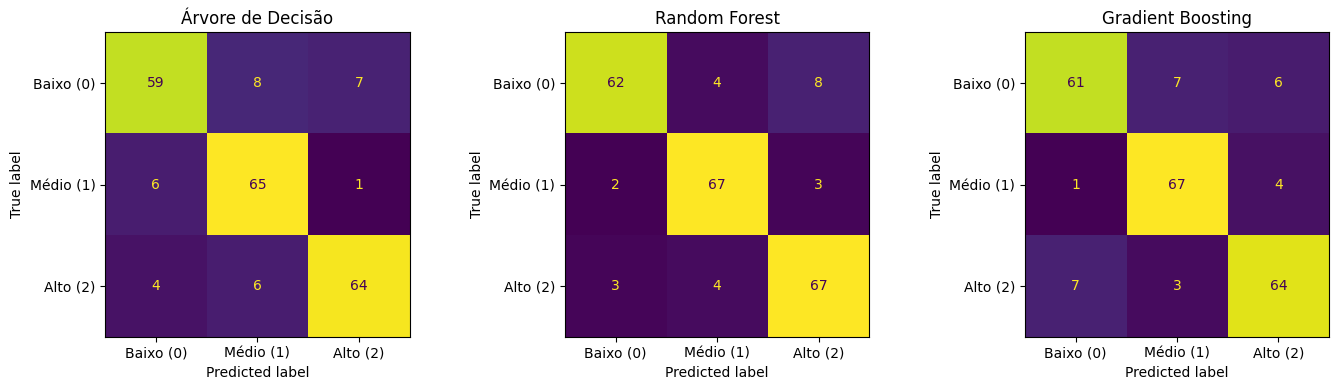

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        display_labels=nomes_classes, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

## 9. Conclusão

Foram comparados três modelos baseados em árvores: Árvore de Decisão, Random Forest e Gradient Boosting. O Random Forest teve o melhor desempenho, com acurácia de 89,09% (196 acertos em 220 amostras), seguido pelo Gradient Boosting, com 87,27% (192 acertos), e pela Árvore de Decisão, com 85,45% (188 acertos).

A Árvore de Decisão foi o modelo mais fraco, com 32 erros espalhados por todas as classes: 15 casos de estresse baixo foram classificados errado (8 como médio e 7 como alto), 7 de médio (6 como baixo e 1 como alto) e 10 de alto (4 como baixo e 6 como médio). O pior recall foi o do estresse baixo (79,7%), e o F1 médio ficou em 0,85. Esse resultado é esperado, pois uma única árvore tende a se ajustar demais aos dados de treino e generaliza pior que os métodos de ensemble.

O Random Forest e o Gradient Boosting tiveram 24 e 28 erros, respectivamente, e os dois acertaram 67 dos 72 casos de estresse médio (recall de 93,1%), a classe mais fácil de identificar. A diferença entre eles está nos extremos. O Random Forest teve recall de 83,8% no estresse baixo e de 90,5% no alto (F1 médio de 0,89), enquanto o Gradient Boosting teve 82,4% e 86,5% (F1 médio de 0,87).

Neste problema, o erro mais grave é classificar um estudante com estresse alto como baixo ou médio, pois o caso que mais precisa de atenção passa despercebido. Por isso o recall da classe alta é a métrica mais relevante, e o Random Forest foi o melhor também nesse critério: deixou de identificar 7 casos de estresse alto, contra 10 do Gradient Boosting e da Árvore de Decisão. Ainda assim, o conjunto de teste tem 220 amostras, e cada erro equivale a cerca de 0,45 ponto percentual. A vantagem do Random Forest sobre o Gradient Boosting é de 4 amostras, o que sugere, mas não prova, que ele seja superior.

# **COMPARAÇÃO SVM x MODELOS BASEADOS EM ÁRVORES**

In [ ]:
# COMPARAÇÃO FINAL DOS MODELOS
# Reúne as previsões dos 4 modelos (SVM com GridSearch, Árvore de Decisão, Random Forest
# e Gradient Boosting) e calcula as mesmas métricas para todos, no mesmo conjunto de teste.
#
# Como o alvo (stress_level) tem 3 classes, as métricas de precisão, recall e F1 usam
# média macro (média simples entre as classes). Também é contado o total de erros e,
# separadamente, os erros mais graves: casos de estresse ALTO previstos como baixo/médio.
#
# A tabela é ordenada pela maior acurácia; em caso de empate, pelo menor número de erros graves.
# Obs.: o SVM passou por GridSearch; as árvores usam os parâmetros padrão.

previsoes_final = {'SVM (GridSearch)': grid.best_estimator_.predict(X_test), **previsoes}

linhas = []
for nome, y_pred in previsoes_final.items():
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
    erros = int(cm.sum() - cm.trace())
    alto_subestimado = int(cm[2, 0] + cm[2, 1])  # estresse alto previsto como baixo/médio
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    linhas.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_test, y_pred),
        'Erros': erros,
        'Alto subestimado': alto_subestimado,
        'Recall alto': cm[2, 2] / cm[2].sum(),
        'Precisão (macro)': p,
        'Recall (macro)': r,
        'F1 (macro)': f1,
    })

tabela = pd.DataFrame(linhas).sort_values(['Acurácia', 'Alto subestimado'], ascending=[False, True]).reset_index(drop=True)
tabela.round(4)

,Modelo,Acurácia,Erros,Alto subestimado,Recall alto,Precisão (macro),Recall (macro),F1 (macro)
0,Random Forest,0.8909,24,7,0.9054,0.8926,0.8913,0.8909
1,SVM (GridSearch),0.8864,25,8,0.8919,0.8928,0.8865,0.8884
2,Gradient Boosting,0.8727,28,10,0.8649,0.8730,0.8732,0.8724
3,Árvore de Decisão,0.8545,32,10,0.8649,0.8556,0.8550,0.8543


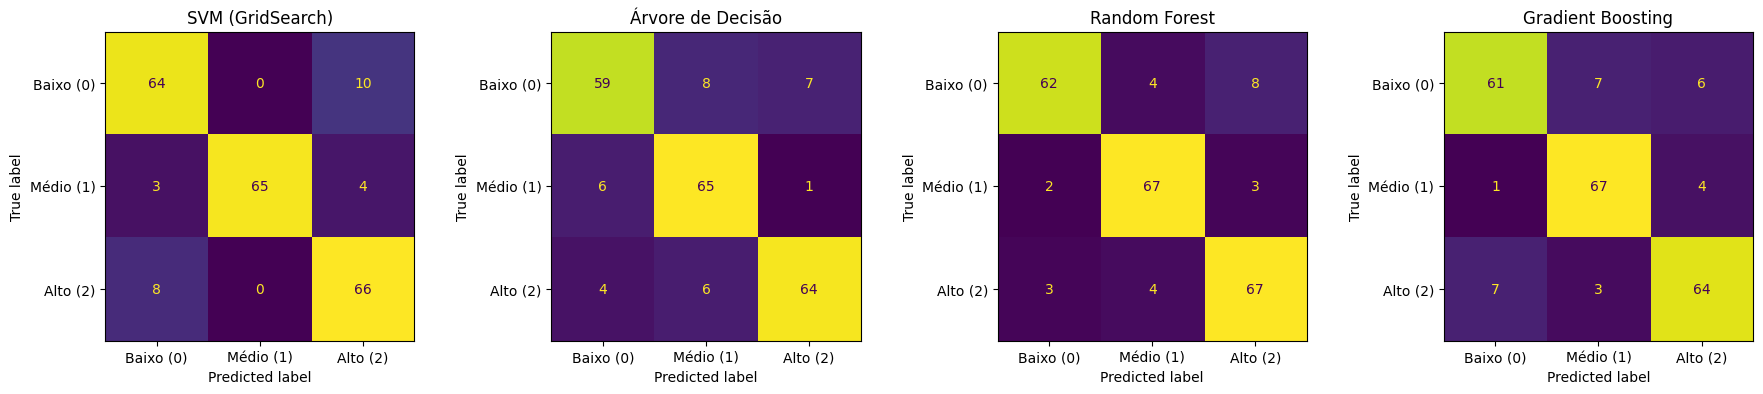

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nome, y_pred) in zip(axes, previsoes_final.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        display_labels=nomes_classes, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

Neste trabalho foram avaliados quatro classificadores para prever o nível de estresse de estudantes (baixo, médio ou alto) a partir de 20 variáveis numéricas sobre fatores psicológicos, fisiológicos, ambientais, acadêmicos e sociais: SVM com ajuste de hiperparâmetros por GridSearch, Árvore de Decisão, Random Forest e Gradient Boosting. Todos foram avaliados no mesmo conjunto de teste, com 220 amostras (74 de estresse baixo, 72 de médio e 74 de alto), o que permite uma comparação direta.

Desempenho geral. O Random Forest obteve a melhor acurácia (89,09%, com 24 erros), seguido pelo SVM com kernel sigmoid, C = 0,1 e gamma = 0,1 (88,64%, 25 erros), pelo Gradient Boosting (87,27%, 28 erros) e pela Árvore de Decisão (85,45%, 32 erros). O F1 médio foi de 0,89 para o Random Forest e para o SVM, 0,87 para o Gradient Boosting e 0,85 para a Árvore de Decisão. A acurácia do SVM na validação cruzada (88,64%) foi igual à do teste, o que indica boa generalização, sem sinais de overfitting.

Modelos baseados em árvores. A Árvore de Decisão foi a de pior desempenho, com erros espalhados pelas três classes. Os métodos de ensemble corrigiram esse problema ao combinar várias árvores: o Random Forest, que faz a média de árvores independentes, reduziu os erros de 32 para 24, e o Gradient Boosting, que treina árvores em sequência corrigindo os erros das anteriores, reduziu para 28.

Análise por tipo de erro. Os erros não têm o mesmo peso. Confundir estresse alto com baixo ou médio é o mais grave, pois deixa de identificar quem mais precisa de atenção. Nesse critério, o Random Forest deixou passar 7 casos de estresse alto (recall de 90,5%), o SVM 8 (89,2%), e o Gradient Boosting e a Árvore de Decisão 10 cada (86,5%). Também importa a distância do erro, já que confundir baixo com alto é pior que confundir níveis vizinhos. Os erros do SVM se concentraram nos extremos: 18 dos 25 foram entre baixo e alto, e a classe média teve precisão de 100% (as 65 previsões de estresse médio estavam corretas). No Random Forest foram 11 dos 24 erros entre baixo e alto, e os outros 13 envolveram a classe média.

SVM versus ensembles. O SVM, mesmo com ajuste, não superou o Random Forest com parâmetros padrão. O ganho do GridSearch sobre o SVM padrão foi de apenas 2 amostras (de 87,73% para 88,64%), e o melhor C (0,1) ficou no menor valor da grade, então valores menores poderiam ser testados. O kernel sigmoid foi o escolhido entre os quatro testados, mas, sem os resultados dos demais kernels, não é possível concluir que a relação entre as variáveis e o estresse seja fortemente não linear.

Limitações. O conjunto de teste é pequeno, e cada erro equivale a cerca de 0,45 ponto percentual de acurácia. A diferença entre o Random Forest (24 erros) e o SVM (25 erros) é de uma única amostra, portanto não permite afirmar que um seja superior ao outro; já a diferença para a Árvore de Decisão (32 erros) é mais expressiva. Além disso, o SVM passou por GridSearch, enquanto as árvores usaram parâmetros padrão, o que favorece o SVM na comparação. Para uma análise mais robusta, seria recomendável avaliar todos os modelos com validação cruzada repetida e aplicar o mesmo ajuste de hiperparâmetros às árvores.

Conclusão. O Random Forest e o SVM tiveram desempenho praticamente igual, com leve vantagem do Random Forest em acurácia e em recall do estresse alto. Os dois ficaram à frente do Gradient Boosting e, com folga, da Árvore de Decisão individual. Nenhum modelo passou de 90% de acurácia, então cerca de 1 em cada 9 estudantes ainda é classificado no nível errado.

# **Fishmorph com o modelo SVM com 4 kernels, C e gamma**

## 1. Fazendo as importações e visualizando o dataset

In [ ]:
import kagglehub
path = kagglehub.dataset_download("menegidio/fishmorph-dataset")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


import os
fish = pd.read_csv(os.path.join(path, 'FISHMORPH_Order_Dataset.csv'))

print(fish.shape)
print(fish.head())

## 2. Tratando os dados

In [ ]:
print(fish.info())

In [ ]:
print('Dados nulos: ')
print(fish.isnull().sum())

In [ ]:
print('Duplicados: ')
print(fish.duplicated().sum())

In [ ]:
# O alvo é a Ordem (Order). Colunas que identificam a espécie ou que já carregam a classificação
# taxonômica (Superorder, Family, Genus, Species...) precisam sair, senão o modelo "descobre" a ordem
# pela família/gênero em vez de aprender com as medidas morfológicas (vazamento de dados).
alvo = next((c for c in fish.columns if c.lower() == 'order'), None)
if alvo is None:
    raise ValueError(f'Coluna alvo (Order) não encontrada. Colunas disponíveis: {list(fish.columns)}')

colunas_remover = ['superorder', 'family', 'genus', 'species', 'genus species', 'genus_species', 'speccode',
                   'scientificnamestd', 'type of illustration', 'reference', 'id', 'unnamed: 0']
remover = [c for c in fish.columns if c.lower() in colunas_remover]
print('Colunas removidas:', remover)
fish = fish.drop(columns=remover)

# o modelo só trabalha com números: ficam apenas as variáveis numéricas (medidas morfológicas) e o alvo
colunas_numericas = fish.drop(columns=[alvo]).select_dtypes(include='number').columns.tolist()
ignoradas = [c for c in fish.columns if c != alvo and c not in colunas_numericas]
print('Variáveis numéricas (X):', colunas_numericas)
print('Colunas não numéricas ignoradas:', ignoradas)
if len(colunas_numericas) < 3:
    raise ValueError('Poucas variáveis numéricas encontradas, confira os tipos das colunas (fish.dtypes).')
fish = fish[colunas_numericas + [alvo]].copy()

In [ ]:
fish = fish.dropna()
print(fish.shape)

In [ ]:
fish = fish.drop_duplicates()
print(fish.shape)

In [ ]:
print(fish.shape)
print(fish.info())

## 3. Definindo o alvo, removendo ordens raras e codificando

In [ ]:
print(fish[alvo].value_counts())

In [ ]:
# Ordens com pouquíssimos exemplos não permitem dividir treino/teste de forma estratificada nem fazer
# validação cruzada em 5 partes. Por isso ficam apenas as ordens com pelo menos min_amostras espécies.
min_amostras = 10
contagem = fish[alvo].value_counts()
ordens_raras = contagem[contagem < min_amostras].index.tolist()
print('Ordens removidas (menos de', min_amostras, 'amostras):', ordens_raras)
fish = fish[~fish[alvo].isin(ordens_raras)].copy()
print(fish.shape)

In [ ]:
# o alvo (Order) é texto, então é transformado em número. O LabelEncoder guarda os nomes em le.classes_
le = LabelEncoder()
fish[alvo] = le.fit_transform(fish[alvo])
classes = le.classes_
print(alvo, ':', list(classes))

print(fish.dtypes)

## 4. Dividindo os dados em X e y

In [ ]:
X = fish.drop(columns=[alvo])

y = fish[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

## 5. SVM com GridSearch e 4 kernels, C e gamma

In [ ]:
model = Pipeline([('scaler', StandardScaler()), ('svm', SVC())])

param_grid = {
    'svm__kernel': ['linear', 'rbf', 'sigmoid', 'poly'],

    'svm__C': [0.1, 1, 10, 100],

    'svm__gamma': [0.001, 0.01, 0.1, 1]
}

grid = GridSearchCV(model, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)

grid.fit(X_train, y_train)

print(grid.best_params_)

## 6. Resultados

In [ ]:
from sklearn.metrics import f1_score, classification_report
import numpy as np

print('Modelo: SVM')

svm_base = Pipeline([('scaler', StandardScaler()), ('svm', SVC())]) # cria um svm base, parametros padrões para servir de comparação
svm_base.fit(X_train, y_train) #treina o modelo base

acc_base = accuracy_score(y_test, svm_base.predict(X_test)) # calcula a acuracia do MODELO base nos dados de teste

y_pred = grid.best_estimator_.predict(X_test) # faz a previsão do teste com o melhor modelo encontrado pelo GridSearch

accuracy = accuracy_score(y_test, y_pred) # calcula a acuracia desse modelo no teste
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0) # F1 médio entre as ordens (cada ordem pesa igual)

print('Melhores parametros: ', grid.best_params_)
print('Acuracia na validação cruzada: ', grid.best_score_)
print('Acuracia do SVM(base): ', acc_base)
print('Acuracia do GridSearch: ', accuracy) # acuracia do modelo otimizado no teste
print('F1 macro do GridSearch: ', f1_macro)

In [ ]:
# desempenho do melhor SVM em cada ordem
print(classification_report(y_test, y_pred, labels=np.arange(len(classes)), target_names=classes, zero_division=0))

## 7. Matriz de Confusão

In [ ]:
# como são muitas ordens e elas têm tamanhos bem diferentes, a matriz é normalizada por linha:
# cada linha mostra, para uma ordem real, a proporção que o modelo previu em cada coluna
fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=np.arange(len(classes)), display_labels=classes,
    normalize='true', include_values=False, cmap='Purples',
    xticks_rotation='vertical', ax=ax
)
ax.set_title('SVM (GridSearch)')

plt.tight_layout()
plt.show()

## 8. Conclusão

In [ ]:
# CONCLUSÃO DO SVM
# O texto é montado automaticamente com os números do modelo treinado acima.
cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(classes)))
total = int(cm.sum())
acertos = int(cm.trace())
erros = total - acertos
recall_ordem = pd.Series(cm.diagonal() / np.maximum(cm.sum(axis=1), 1), index=classes)
suporte = pd.Series(cm.sum(axis=1), index=classes)

p = grid.best_params_
kernel, C, gamma = p['svm__kernel'], p['svm__C'], p['svm__gamma']
txt_gamma = 'gamma não é usado no kernel linear' if kernel == 'linear' else f'gamma = {gamma}'

print(f'O melhor modelo foi o SVM com kernel {kernel}, C = {C} e {txt_gamma}. '
      f'A acurácia média na validação cruzada foi de {grid.best_score_:.2%} e, no conjunto de teste, de {accuracy:.2%} '
      f'(contra {acc_base:.2%} do SVM com parâmetros padrão). O modelo acertou {acertos} das {total} amostras de teste '
      f'e o F1 macro foi de {f1_macro:.2%}.')

dif = abs(grid.best_score_ - accuracy)
print(f'\nA diferença entre validação cruzada e teste foi de {dif:.2%}'
      + (', o que indica boa generalização, sem sinais de overfitting.' if dif < 0.03 else ', o que merece atenção por ser relativamente grande.'))

melhores = recall_ordem.sort_values(ascending=False).head(3)
piores = recall_ordem.sort_values().head(3)
print('\nOrdens mais bem identificadas (recall): '
      + '; '.join(f'{o} ({r:.1%}, {int(suporte[o])} amostras no teste)' for o, r in melhores.items()) + '.')
print('Ordens mais difíceis (recall): '
      + '; '.join(f'{o} ({r:.1%}, {int(suporte[o])} amostras no teste)' for o, r in piores.items()) + '.')

fora = cm.copy()
np.fill_diagonal(fora, 0)
top = np.argsort(-fora.ravel())[:3]
conf = [(classes[i // len(classes)], classes[i % len(classes)], int(fora.ravel()[i])) for i in top if fora.ravel()[i] > 0]
if conf:
    print('\nConfusões mais frequentes: '
          + '; '.join(f'{a} previsto como {b} ({n} casos)' for a, b, n in conf) + '.')

if C in (min(param_grid['svm__C']), max(param_grid['svm__C'])):
    print(f'\nO melhor C ({C}) ficou no limite da grade, então valores além dele poderiam ser testados.')
print(f'\nO conjunto de teste tem {total} amostras, então cada erro equivale a cerca de {100/total:.2f} ponto percentual de acurácia.')

# **Fishmorph com Arvore de decisão, Random Forest e Boosting**

## 1. Importando bibliotecas

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score,
                             f1_score, balanced_accuracy_score)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import kagglehub
path = kagglehub.dataset_download("menegidio/fishmorph-dataset")

import os

fish = pd.read_csv(os.path.join(path, 'FISHMORPH_Order_Dataset.csv'))

print(fish.shape)

print(fish.head())

## 2. Análise dos dados e limpeza

In [ ]:
print(fish.info())

In [ ]:
print('Dados nulos: ')
print(fish.isnull().sum())

In [ ]:
print('Duplicados: ')
print(fish.duplicated().sum())

In [ ]:
# mesma limpeza usada no SVM: remove colunas taxonômicas/identificadoras (evita vazamento do alvo),
# mantém só as medidas numéricas, remove nulos e duplicados
alvo = next((c for c in fish.columns if c.lower() == 'order'), None)
if alvo is None:
    raise ValueError(f'Coluna alvo (Order) não encontrada. Colunas disponíveis: {list(fish.columns)}')

colunas_remover = ['superorder', 'family', 'genus', 'species', 'genus species', 'genus_species', 'speccode',
                   'scientificnamestd', 'type of illustration', 'reference', 'id', 'unnamed: 0']
remover = [c for c in fish.columns if c.lower() in colunas_remover]
print('Colunas removidas:', remover)
fish = fish.drop(columns=remover)

colunas_numericas = fish.drop(columns=[alvo]).select_dtypes(include='number').columns.tolist()
print('Variáveis numéricas (X):', colunas_numericas)
fish = fish[colunas_numericas + [alvo]].copy()

fish = fish.dropna()
fish = fish.drop_duplicates()
print(fish.shape)

## 3. Transformação numérica

In [ ]:
# mesmo critério do SVM: ordens com menos de min_amostras espécies ficam de fora
min_amostras = 10
contagem = fish[alvo].value_counts()
ordens_raras = contagem[contagem < min_amostras].index.tolist()
print('Ordens removidas (menos de', min_amostras, 'amostras):', ordens_raras)
fish = fish[~fish[alvo].isin(ordens_raras)].copy()

le = LabelEncoder()
fish[alvo] = le.fit_transform(fish[alvo])
classes = le.classes_
print(alvo, ':', list(classes))

print(fish.dtypes)

## 4. Divisão X e y, treino e teste

In [ ]:
X = fish.drop(columns=[alvo])

y = fish[alvo]

X_train, X_test, y_train, y_test = train_test_split (
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 5. Criação e treinamento dos modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f'{nome}: treinado')

## 6. Previsões nos dados de teste

In [ ]:
previsoes = {nome: modelo.predict(X_test) for nome, modelo in modelos.items()}
print('Valores reais:', y_test.values)
for nome, y_pred in previsoes.items():
    print(f'{nome}:  ', y_pred)

## 7. Avaliação e comparação

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    f1_pond = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia, 'Precisão (macro)': p, 'Recall (macro)': r,
                       'F1 (macro)': f1, 'F1 (ponderado)': f1_pond})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, labels=np.arange(len(classes)), target_names=classes, zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False).round(4)

## 8. Matriz de confusão

In [ ]:
# uma matriz por modelo, normalizada por linha (proporção de cada ordem real prevista em cada coluna)
for nome, y_pred in previsoes.items():
    fig, ax = plt.subplots(figsize=(12, 10))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=np.arange(len(classes)),
        display_labels=classes, normalize='true', include_values=False, cmap='Purples',
        xticks_rotation='vertical', ax=ax)
    ax.set_title(nome)
    plt.tight_layout()
    plt.show()

## 9. Conclusão

In [ ]:
# CONCLUSÃO DAS ÁRVORES
# O texto é montado automaticamente com os números dos modelos treinados acima.
tab = pd.DataFrame(resultados).sort_values('Acurácia', ascending=False).reset_index(drop=True)
total = len(y_test)
acertos = {l['Modelo']: int(round(l['Acurácia'] * total)) for _, l in tab.iterrows()}

ranking = ', '.join(f"{l['Modelo']} ({l['Acurácia']:.2%}, {acertos[l['Modelo']]} acertos)" for _, l in tab.iterrows())
print(f'Foram comparados três modelos baseados em árvores no mesmo conjunto de teste ({total} amostras). '
      f'Do melhor para o pior em acurácia: {ranking}.')

melhor, pior = tab.iloc[0], tab.iloc[-1]
dif = acertos[melhor['Modelo']] - acertos[pior['Modelo']]
print(f"\nO {melhor['Modelo']} teve o melhor desempenho, com F1 macro de {melhor['F1 (macro)']:.2%} e F1 ponderado de {melhor['F1 (ponderado)']:.2%}. "
      f"Ele acertou {dif} amostras a mais que o {pior['Modelo']}, o modelo de menor acurácia.")
print(f'Cada erro equivale a cerca de {100/total:.2f} ponto percentual, então diferenças de poucas amostras entre modelos próximos não são conclusivas.')

if melhor['F1 (macro)'] < melhor['Acurácia'] - 0.05:
    print(f"\nO F1 macro ({melhor['F1 (macro)']:.2%}) ficou abaixo da acurácia ({melhor['Acurácia']:.2%}). "
          'Isso indica que as ordens com poucos exemplos são mais difíceis de identificar que as ordens grandes, que puxam a acurácia para cima.')

if 'Árvore de Decisão' in tab['Modelo'].values and tab.iloc[0]['Modelo'] != 'Árvore de Decisão':
    print('\nA Árvore de Decisão individual ficou atrás de pelo menos um método de ensemble, resultado esperado, '
          'já que uma única árvore tende a se ajustar demais aos dados de treino.')

# **COMPARAÇÃO SVM x MODELOS BASEADOS EM ÁRVORES**

In [ ]:
# COMPARAÇÃO FINAL DOS MODELOS
# Reúne as previsões dos 4 modelos (SVM com GridSearch, Árvore de Decisão, Random Forest
# e Gradient Boosting) e calcula as mesmas métricas para todos, no mesmo conjunto de teste.
#
# Como o alvo (Order) tem muitas classes de tamanhos bem diferentes, além da acurácia são mostradas
# a acurácia balanceada (média do recall de cada ordem) e o F1 macro (média simples entre as ordens),
# que dão o mesmo peso para ordens grandes e pequenas, e o F1 ponderado, que pesa pelo tamanho de cada ordem.
#
# A tabela é ordenada pela maior acurácia.
# Obs.: o SVM passou por GridSearch; as árvores usam os parâmetros padrão.

previsoes_final = {'SVM (GridSearch)': grid.best_estimator_.predict(X_test), **previsoes}

linhas = []
for nome, y_pred in previsoes_final.items():
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    linhas.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_test, y_pred),
        'Acurácia balanceada': balanced_accuracy_score(y_test, y_pred),
        'Erros': int((y_test != y_pred).sum()),
        'Precisão (macro)': p,
        'Recall (macro)': r,
        'F1 (macro)': f1,
        'F1 (ponderado)': f1_score(y_test, y_pred, average='weighted', zero_division=0),
    })

tabela = pd.DataFrame(linhas).sort_values('Acurácia', ascending=False).reset_index(drop=True)
tabela.round(4)

In [ ]:
tabela.set_index('Modelo')[['Acurácia', 'Acurácia balanceada', 'F1 (macro)']].plot(
    kind='bar', figsize=(10, 5), colormap='Purples_r', edgecolor='black')
plt.title('Comparação dos modelos no conjunto de teste')
plt.ylabel('Métrica')
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Conclusão final

In [ ]:
# CONCLUSÃO FINAL
# O texto é montado automaticamente com os números da tabela de comparação.
total = len(y_test)
t = tabela.copy()
melhor = t.iloc[0]
svm = t[t['Modelo'] == 'SVM (GridSearch)'].iloc[0]
pos_svm = int(t.index[t['Modelo'] == 'SVM (GridSearch)'][0]) + 1
melhor_f1 = t.sort_values('F1 (macro)', ascending=False).iloc[0]

print(f'Neste trabalho foram avaliados quatro classificadores para prever a ordem taxonômica de peixes de água doce '
      f'a partir de {X.shape[1]} medidas morfológicas: SVM com ajuste de hiperparâmetros por GridSearch, Árvore de Decisão, '
      f'Random Forest e Gradient Boosting. Foram consideradas {len(classes)} ordens, e todos os modelos foram avaliados no mesmo '
      f'conjunto de teste, com {total} amostras.')

print('\nDesempenho geral. ' + '; '.join(
    f"{l['Modelo']}: acurácia {l['Acurácia']:.2%} ({l['Erros']} erros), F1 macro {l['F1 (macro)']:.2%}"
    for _, l in t.iterrows()) + '.')

p = grid.best_params_
print(f"\nO SVM ficou em {pos_svm}º lugar em acurácia, com kernel {p['svm__kernel']}, C = {p['svm__C']}"
      + ('' if p['svm__kernel'] == 'linear' else f", gamma = {p['svm__gamma']}")
      + f". A acurácia dele na validação cruzada foi de {grid.best_score_:.2%}, contra {svm['Acurácia']:.2%} no teste.")

if melhor['Modelo'] != melhor_f1['Modelo']:
    print(f"\nO melhor modelo em acurácia ({melhor['Modelo']}) não é o melhor em F1 macro ({melhor_f1['Modelo']}), "
          'o que mostra que o desempenho nas ordens pequenas muda a classificação dos modelos.')
else:
    print(f"\nO {melhor['Modelo']} foi o melhor tanto em acurácia quanto em F1 macro.")

print(f"\nLimitações. O conjunto de teste tem {total} amostras, e cada erro equivale a cerca de {100/total:.2f} ponto percentual. "
      f"Ordens com menos de {min_amostras} espécies foram removidas ({len(ordens_raras)} ordens), então o resultado não vale para elas. "
      'As ordens são muito desbalanceadas, por isso a acurácia sozinha favorece as ordens grandes. '
      'O SVM passou por GridSearch, enquanto as árvores usaram parâmetros padrão, o que favorece o SVM na comparação. '
      'Para uma análise mais robusta, seria recomendável avaliar todos os modelos com validação cruzada repetida '
      'e aplicar o mesmo ajuste de hiperparâmetros às árvores.')